This file is for calculating the final result from GRMHD simulations and EHT-Imaging.


What is needed:

-   `GRMHD/grmhdDataAfterImageS.npy`
-   `GRMHD/EVPA.npy`
-   `NormR.csv`


# libraries, functions, ...


In [1]:
import numpy as np
from copy import deepcopy
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from utils.libanaly import Plot_Background, plot_quivers, CircleCalc, ImageS
from scipy.linalg import cho_factor, cho_solve

# Part GRMHD: calucate std or cor (without Axion)


What we get:

-   `cor_grmhd` it is a number (rad) representing the standard deviation of different time GRMHD simulations


In [2]:
grmhdDataAfterImageS = np.load(
    "./GRMHD/data_out/grmhdDataAfterImageS_alpha=0.3_res=400.npy"
)
EVPA = np.load("./GRMHD/data_out/EVPA_alpha=0.3_res=400.npy")  # rad
# EVPA_without_axion = EVPA[:, 0, :, :]

In [3]:
# P_without_axion = np.sqrt(
#     grmhdDataAfterImageS[:, 0, :, :, 1] ** 2 + grmhdDataAfterImageS[:, 0, :, :, 2] ** 2
# )

In [4]:
grmhdDataAfterImageS = {}
EVPA = {}
EVPA_1d = {}
EVPA_1d_10deg = {}

for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    grmhdDataAfterImageS[alpha] = np.load(
        f"GRMHD/data_out/grmhdDataAfterImageS_alpha={alpha}_res=100.npy"
    )
    EVPA[alpha] = np.load(f"GRMHD/data_out/EVPA_alpha={alpha}_res=100.npy")
    EVPA_1d[alpha] = np.load(f"GRMHD/data_out/EVPA_1d_alpha={alpha}_res=100.npy")
    EVPA_1d_10deg[alpha] = np.load(
        f"GRMHD/data_out/EVPA_1d_10deg_alpha={alpha}_res=100.npy"
    )

grmhdDataAfterImageS_400 = {}
EVPA_400 = {}
EVPA_400_1d = {}
EVPA_400_1d_10deg = {}

for alpha in [0.3]:
    grmhdDataAfterImageS_400[alpha] = np.load(
        f"GRMHD/data_out/grmhdDataAfterImageS_alpha={alpha}_res=400.npy"
    )
    EVPA_400[alpha] = np.load(f"GRMHD/data_out/EVPA_alpha={alpha}_res=400.npy")
    EVPA_400_1d[alpha] = np.load(f"GRMHD/data_out/EVPA_1d_alpha={alpha}_res=400.npy")
    EVPA_400_1d_10deg[alpha] = np.load(
        f"GRMHD/data_out/EVPA_1d_10deg_alpha={alpha}_res=400.npy"
    )

In [5]:
rg_per_pixel = 0.51073125
condition2to9 = np.array(
    [
        [
            2 <= np.sqrt((i - 31.5) ** 2 + (j - 31.5) ** 2) * rg_per_pixel <= 9
            for j in range(64)
        ]
        for i in range(64)
    ]
)
threshold = 0.1e9


# 注意由于这里求的都是不含轴子效应的结果，所以理应与alpha无关
def get_EVPA_diff_xday(diff, alpha=0.3):
    start = 1600
    end = 3000
    grmhd_step = 10
    step = 30  # 30 * 0.1 *8h=1day
    r_step = step // grmhd_step

    diff_x_r_step = int(diff * r_step)
    evpa_diff_temp = np.zeros(((end - start) // grmhd_step - diff_x_r_step + 1, 64, 64))
    evpa_diff_temp_with_condition = np.zeros(
        ((end - start) // grmhd_step - diff_x_r_step + 1, 64, 64)
    )
    EVPA_without_axion = EVPA_400[alpha][:, 0, :, :]
    P_without_axion = np.sqrt(
        grmhdDataAfterImageS_400[alpha][:, 0, :, :, 1] ** 2
        + grmhdDataAfterImageS_400[alpha][:, 0, :, :, 2] ** 2
    )
    for num in range((end - start) // grmhd_step - diff_x_r_step + 1):
        evpa_diff_temp[num] = CircleCalc.circle_sub_evpa(
            EVPA_without_axion[num + diff_x_r_step], EVPA_without_axion[num]
        )
        condition = (
            (P_without_axion[num + diff_x_r_step] > threshold)
            * (P_without_axion[num] > threshold)
            * condition2to9
        )  # can be optimized
        evpa_diff_temp_with_condition[num] = evpa_diff_temp[num] * condition
        evpa_diff_temp_with_condition[num][
            evpa_diff_temp_with_condition[num] == 0
        ] = np.nan
    return evpa_diff_temp, evpa_diff_temp_with_condition


def get_EVPA_diff_1day(**kwargs):
    return get_EVPA_diff_xday(1, **kwargs)


def get_EVPA_diff_8h(**kwargs):
    return get_EVPA_diff_xday(1 / 3, **kwargs)

In [6]:
evpa_diff, evpa_diff_with_condition = get_EVPA_diff_1day()

In [7]:
# def gaussian(x, amplitude, mean, stddev):
#     return (
#         amplitude
#         / np.sqrt(2 * np.pi)
#         / stddev
#         * np.exp(-(((x - mean) / stddev) ** 2) / 2)
#     )


# def _gaussian_noAmp(x, mean, sigma):
#     return gaussian(x, 1, mean, sigma)


# def plot_gaussian1(
#     data_temp,
#     bins=100,
#     plot_range=(-7, 7),
#     plot=True,
#     initial_guess=[1, 0, 1],
#     rm_nan=True,
#     figsize=(16, 16),
# ):

#     # 生成随机数据
#     np.random.seed(42)
#     data = deepcopy(data_temp)
#     if rm_nan == True:
#         data = data[np.isfinite(data)]

#     # 生成直方图
#     hist, bin_edges = np.histogram(data, bins=bins, density=True)
#     bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

#     # 初始猜测值
#     # initial_guess = initial_guess

#     # 使用curve_fit进行拟合
#     params, covariance = curve_fit(
#         gaussian, bin_centers, hist, p0=initial_guess, maxfev=5000000
#     )

#     if plot == True:
#         # 绘制直方图
#         fig = plt.figure(figsize=figsize)
#         plt.hist(data, bins=bins, density=True, range=plot_range, color="orange")

#         # 绘制拟合曲线
#         x_range = np.linspace(*plot_range, 100)
#         fit_curve = gaussian(x_range, *params)
#         # "$y="+f"{params[0]:.3f}"+r"\exp{\frac{x-"+f"{params[1]:.3f}"+r"^2}{2\cdot "+f"{params[2]:.3f}"+"^2}}$"
#         plt.plot(
#             x_range,
#             fit_curve,
#             "r-",
#             label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "
#             + f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",
#             color="brown",
#         )
#         plt.xticks(fontsize=24)
#         plt.yticks(fontsize=24)
#         # plt.xlabel(r"$\frac{\Delta I_{\left("+f"{day}"+r"\mathrm{day}\right)}}{I}$",fontsize=30)
#         # plt.xlabel(r"$\Delta EVPA _{\left("+f"{day}"+r"\mathrm{day}\right)}$",fontsize=24)
#         plt.gca().spines["top"].set_visible(False)
#         plt.gca().spines["right"].set_visible(False)
#         plt.legend(fontsize=24)
#         plt.show()

#     return params, covariance

In [8]:
# plt.imshow(evpa_diff_with_condition[10], cmap="jet")
# plt.colorbar()

In [9]:
# plt.imshow(evpa_diff_with_condition[0], cmap="jet")
# plt.colorbar()

In [10]:
from utils.libanaly import plot_gaussian, fit_gaussian2

In [11]:
_, _cor_grmhd_tmp_ = fit_gaussian2(
    evpa_diff_with_condition.reshape(-1, 1)[:, 0] / np.pi * 180,
    rm_nan=True,
    bins=100,
    threshold=0.2,
)

/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:107: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


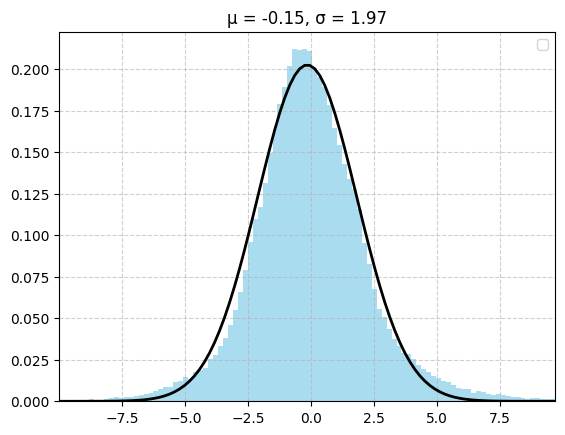

In [12]:
plot_gaussian(
    evpa_diff_with_condition.reshape(-1, 1)[:, 0] / np.pi * 180,
    bins=100,
    mean=-0.147,
    sigma=1.97,
)

In [13]:
# _cor_grmhd_tmp_ = plot_gaussian1(
#     evpa_diff_with_condition.reshape(-1, 1)[:, 0] / np.pi * 180,
#     bins=100,
#     plot_range=(-7, 7),
#     plot=True,
#     initial_guess=[1, 0, 1],
#     rm_nan=True,
#     figsize=(16, 15),
# )[0][2]

In [14]:
cor_grmhd = np.identity(64 * 64) * (_cor_grmhd_tmp_ / 180 * np.pi) ** 2

In [15]:
def make_interpolator(axion_evpa_diffs_std_16phase):
    """
    给定一个 {alpha: ndarray(16,64,64)} 的字典，
    返回一个插值函数 f(alpha)，输出线性插值结果。
    """
    # 提取并排序 alpha 值
    alphas = np.array(sorted(axion_evpa_diffs_std_16phase.keys()))

    # 将数据堆叠为 (N_alpha, 16, 64, 64)
    data = np.stack([axion_evpa_diffs_std_16phase[a] for a in alphas])

    def f(alpha):
        # 若超出范围，则截断在边界
        if alpha <= alphas[0]:
            return data[0]
        if alpha >= alphas[-1]:
            return data[-1]

        # 找到相邻区间
        idx = np.searchsorted(alphas, alpha) - 1
        a0, a1 = alphas[idx], alphas[idx + 1]
        w = (alpha - a0) / (a1 - a0)

        # 线性插值
        return (1 - w) * data[idx] + w * data[idx + 1]

    return f

# Part Axion


In [16]:
def _omega(alpha):
    return alpha * (1 - alpha**2 / 2 / (2 + 1 + 1) ** 2)

In [17]:
alpha_grmhd = 0.3
omega_grmhd = _omega(alpha_grmhd)
axion_norm = 0.1  # check it
g_res = 40
gagg = np.logspace(np.log10(1 / 137.0), 2, g_res)

In [18]:
# EVPA_fit_result = np.load("./GRMHD/EVPA_fit_result.npy")  # rad

我们没有跑不同 omega 下的 axion 随 grmhd 演化的效应。因此需要把在 omega=0.4 情况下的 diffs_axion_evpa 结果 rescale 到所有的情况。使用不同 omega 时 photon ring 的半径上的 axion 强度来 rescale。

错误的，现在跑了


In [19]:
# import pandas as pd
# from scipy.interpolate import RegularGridInterpolator


# def load_and_interpolate(csv_file):
#     # 读取CSV文件
#     df = pd.read_csv(csv_file, header=None, names=["omega", "R", "f"])

#     # 获取唯一的omega和R值
#     omega_values = np.unique(df["omega"].values)
#     R_values = np.unique(df["R"].values)

#     # 创建二维插值网格
#     f_values = df.pivot(index="omega", columns="R", values="f").values

#     # 创建插值函数
#     interpolator = RegularGridInterpolator(
#         (omega_values, R_values), f_values, bounds_error=False, fill_value=None
#     )

#     def _f(omega, R):
#         # 计算插值
#         return interpolator((omega, R))

#     return _f

In [20]:
# R_photon_ring = (246 - 157) / 400 * 2 * 23.1131 / 2

In [21]:
# f_axion_norm = load_and_interpolate("NormR.csv")

## every pixel, find sigma of diffs_axion_evpa over every grmhd


In [22]:
EVPA_cos_fit_result = {}
EVPA_cos_fit_result_1d_10deg = {}
for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    EVPA_cos_fit_result[alpha] = np.load(
        f"GRMHD/data_out/EVPA_cos_fit_result_alpha={alpha}.npy"
    )
    EVPA_cos_fit_result_1d_10deg[alpha] = np.load(
        f"GRMHD/data_out/EVPA_cos_fit_result_1d_10deg_alpha={alpha}.npy"
    )

In [23]:
from utils.libanaly import fit_gaussian, fit_gaussian2

In [ ]:
extra_phase = np.linspace(0, 2 * np.pi, 16)


def get_A_phi0_params():
    # these have different alpha results, and these 2 are mean and std of 1day evpa diff at each pixel
    A_params_dict = {}
    phi0_params_dict = {}
    for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
        # EVPA_without_axion = EVPA[alpha][:, 0, :, :]
        P_without_axion = np.sqrt(
            grmhdDataAfterImageS[alpha][:, 0, :, :, 1] ** 2
            + grmhdDataAfterImageS[alpha][:, 0, :, :, 2] ** 2
        )
        condition = (P_without_axion > threshold) * condition2to9  # ?*64*64 and 64*64
        A_data_list = EVPA_cos_fit_result[alpha][:, :, :, 0] * condition
        A_data_list[A_data_list == 0] = np.nan
        phi0_data_list = EVPA_cos_fit_result[alpha][:, :, :, 1] * condition
        phi0_data_list[phi0_data_list == 0] = np.nan
        A_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            A_data_list,
            rm_nan=True,
            plot_failed=False,
            threshold=0.2,
            p_value_threshold=0.001,
            bins=20,
        )
        A_params_dict[alpha] = A_params
        phi0_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            phi0_data_list,
            rm_nan=True,
            plot_failed=False,
            angle=True,
            lower_bound=-np.pi,
            upper_bound=np.pi,
            threshold=0.2,
            p_value_threshold=0.001,
            bins=20,
        )  # change it
        phi0_params_dict[alpha] = phi0_params
    return A_params_dict, phi0_params_dict


A_params_dict, phi0_params_dict = get_A_phi0_params()

A_params_interpolator = make_interpolator(A_params_dict)
phi0_params_interpolator = make_interpolator(phi0_params_dict)


def axion_evpa_diffs_16phase_1(alpha):
    A_params = A_params_interpolator(alpha)
    phi0_params = phi0_params_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )

    _axion_evpa_diffs_16phase_tmp_1 = np.zeros(
        (
            16,
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[1],
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[2],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_diffs_16phase_tmp_1[i] = (
            constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
        )  # *gagg[g]

    return _axion_evpa_diffs_16phase_tmp_1


def axion_evpa_diffs_16phase_2(alpha):
    A_params = A_params_interpolator(alpha)
    phi0_params = phi0_params_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )

    _axion_evpa_diffs_16phase_tmp_2 = np.zeros(
        (
            16,
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[1],
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[2],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]

        _axion_evpa_diffs_16phase_tmp_2[i] = (
            constant1_axion
            * A_params[0]
            * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
        )  # *gagg[g]

    return _axion_evpa_diffs_16phase_tmp_2


def axion_evpa_diffs_std_16phase(alpha):
    A_params = A_params_interpolator(alpha)
    phi0_params = phi0_params_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )

    _axion_evpa_diffs_std_16phase_tmp = np.zeros(
        (
            16,
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[1],
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[2],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_diffs_std_16phase_tmp[i] = np.sqrt(
            np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
            + np.power(
                constant1_axion
                * A_params[0]
                * np.cos(ep + phi0_params[0])
                * phi0_params[1],
                2,
            )
        )
    return _axion_evpa_diffs_std_16phase_tmp


# for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
#     for i in range(extra_phase.shape[0]):
#         # 需要确定，使用统计结果还是挑选某个特定时间？
#         ep = extra_phase[i]
#         _axion_evpa_diffs_16phase_tmp_1[i] = (
#             constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
#         )  # *gagg[g]

#         _axion_evpa_diffs_16phase_tmp_2[i] = (
#             constant1_axion
#             * A_params[0]
#             * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
#         )  # *gagg[g]

#         _axion_evpa_diffs_std_16phase_tmp[i] = np.sqrt(
#             np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
#             + np.power(
#                 constant1_axion
#                 * A_params[0]
#                 * np.cos(ep + phi0_params[0])
#                 * phi0_params[1],
#                 2,
#             )
#         )
#     axion_evpa_diffs_16phase_1[alpha] = _axion_evpa_diffs_16phase_tmp_1
#     axion_evpa_diffs_16phase_2[alpha] = _axion_evpa_diffs_16phase_tmp_2
#     axion_evpa_diffs_std_16phase[alpha] = _axion_evpa_diffs_std_16phase_tmp

number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0
number left less than minimum effective number: 0


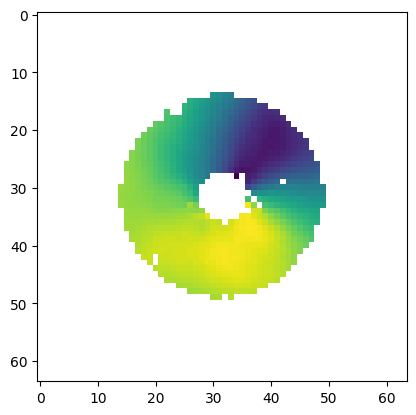

In [24]:
_x = np.zeros((64, 64))
for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    _x += axion_evpa_diffs_16phase_1[alpha][0]
plt.imshow(_x)

In [25]:
# extra_phase = np.linspace(0, 2 * np.pi, 16)


# # 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(ep+phi0)/axion_norm*gagg[g]
# # first calc 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(ep+phi0)/axion_norm
# # and define 2*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)/axion_norm

# condition = (P_without_axion > threshold) * condition2to9  # ?*64*64 and 64*64

# # caution!!! amp should be set
# constant1_axion = (
#     2
#     * np.sin(0.112411 * omega_grmhd / 2 * 24)
#     * np.sin(0.112411 * omega_grmhd / 2 * 6)
#     / (0.112411 * omega_grmhd / 2 * 6)
#     / axion_norm
# )

# diffs_axion_evpa_t = np.zeros((16, EVPA_fit_result.shape[1], EVPA_fit_result.shape[2]))
# diffs_axion_evpa_std_t = np.zeros(
#     (16, EVPA_fit_result.shape[1], EVPA_fit_result.shape[2])
# )

# A_data_list = deepcopy(EVPA_fit_result[:, :, :, 0]) * condition
# A_data_list[A_data_list == 0] = np.nan
# phi0_data_list = deepcopy(EVPA_fit_result[:, :, :, 1]) * condition
# phi0_data_list[phi0_data_list == 0] = np.nan

In [26]:
# def fit_gaussian(
#     data_list,
#     bins_list=[40, 30, 20],
#     initial_guess=[1, 0, 1],
#     rm_nan=False,
#     maxfev=5000000,
#     output=True,
# ):
#     _data = deepcopy(data_list)
#     if rm_nan == True:
#         _data = _data[np.isfinite(_data)]

#     fit_success = False

#     if output:
#         print("------------------fit start-----------------------")

#     for bins in bins_list:
#         if _data.shape[0] < bins:
#             if output:
#                 print("badfit, bins>len(data)")
#             continue
#         hist, bin_edges = np.histogram(_data, bins=bins, density=True)
#         bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
#         initial_guess[0] = 1  # np.shape(_data)[0]
#         initial_guess[1] = bin_centers[np.argmax(hist)]
#         initial_guess[2] = np.std(_data)
#         try:
#             params, covariance = curve_fit(
#                 _gaussian_noAmp, bin_centers, hist, maxfev=maxfev  # p0=initial_guess,
#             )
#         except Exception as e:
#             if output:
#                 print("badfit, error", e)
#             continue
#         # params=np.asarray(params)
#         # covariance=np.asarray(covariance)
#         c1 = abs(covariance[1][1]) / abs(params[1])
#         # c2 = abs(covariance[2][2]) / abs(params[2])
#         # if output:
#         #     print(c1, c2)
#         if c1 < 1:  # and c2 < 1:
#             fit_success = True
#             break
#         else:
#             if output:
#                 print("badfit, cov")
#     if not fit_success:
#         params = np.zeros((3))
#         covariance = np.zeros((3, 3))
#         params[:] = np.nan
#         covariance[:] = np.nan
#     if output:
#         print("fit complete!")
#     return params, covariance


# def fit_gaussian_params(
#     data_list,
#     bins_list=[40, 30, 20],
#     initial_guess=[1, 0, 1],
#     rm_nan=False,
#     maxfev=5000000,
#     output=True,
# ):
#     params, _ = fit_gaussian(
#         data_list,
#         bins_list=bins_list,
#         initial_guess=initial_guess,
#         rm_nan=rm_nan,
#         maxfev=maxfev,
#         output=output,
#     )
#     return params

In [27]:
# # 4min
# A_params = np.apply_along_axis(fit_gaussian_params, 0, A_data_list, rm_nan=True)
# phi0_params = np.apply_along_axis(
#     fit_gaussian_params, 0, phi0_data_list, rm_nan=True
# )  # change it

In [28]:
# # np.save("A_params",A_params)
# # np.save("phi0_params",phi0_params)
# A_params = np.load("A_params.npy")  # amplitude, mean, stddev
# phi0_params = np.load("phi0_params.npy")

In [29]:
# amp = EVPA_fit_result[51, :, :, 0]
# phi0 = EVPA_fit_result[51, :, :, 1]
# for i in range(extra_phase.shape[0]):
#     ep = extra_phase[i]
#     diffs_axion_evpa_t[i] = constant1_axion * amp * np.sin(ep + phi0)  # *gagg[g]
#     diffs_axion_evpa_std_t[i] = np.sqrt(
#         np.power(constant1_axion * np.sin(ep + phi0) * A_params[2], 2)
#         + np.power(constant1_axion * amp * np.cos(ep + phi0) * phi0_params[2], 2)
#     )
# diffs_axion_evpa = np.mean(diffs_axion_evpa_t, axis=0)  # rad
# diffs_axion_evpa_std = np.mean(diffs_axion_evpa_std_t, axis=0)  # rad

In [30]:
# A_params.shape

In [31]:
# np.save("./Plot/diffs_axion_evpa_std.npy", diffs_axion_evpa_std)

In [32]:
# np.save("./Plot/diffs_axion_evpa.npy", diffs_axion_evpa)

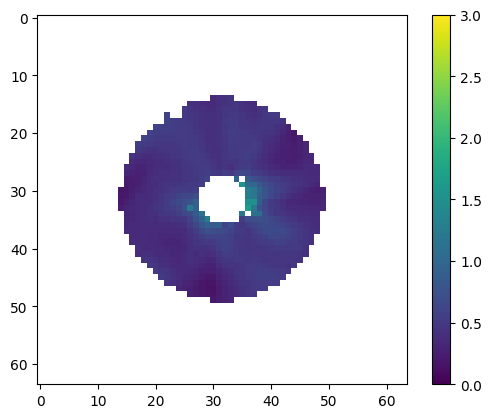

In [33]:
plt.imshow(np.mean(axion_evpa_diffs_std_16phase[0.3], axis=0) / np.pi * 180)
plt.colorbar()
plt.clim(0, 3)

In [34]:
# figure, ax = plt.subplots(figsize=(30, 30))
# Plot_Background(figure, ax, A_params[1] / np.pi * 180)

1d


In [35]:
# # 141,360,3
# EVPA_fit_result_1d = np.load("./GRMHD/EVPA_fit_result_1d.npy")  # rad

In [ ]:
extra_phase = np.linspace(0, 2 * np.pi, 16)
# these have different alpha results, and these 2 are mean and std of 1day evpa diff at each pixel


def get_A_phi0_1d_params():
    A_params_dict = {}
    phi0_params_dict = {}
    for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
        A_data_list = EVPA_cos_fit_result_1d_10deg[alpha][:, :, 0]
        A_data_list[A_data_list == 0] = np.nan
        phi0_data_list = EVPA_cos_fit_result_1d_10deg[alpha][:, :, 1]
        phi0_data_list[phi0_data_list == 0] = np.nan
        A_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            A_data_list,
            rm_nan=True,
            plot_failed=False,
            threshold=0.2,
            p_value_threshold=0.001,
            bins=20,
        )
        A_params_dict[alpha] = A_params
        phi0_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            phi0_data_list,
            rm_nan=True,
            plot_failed=False,
            angle=True,
            lower_bound=-np.pi,
            upper_bound=np.pi,
            threshold=0.2,
            p_value_threshold=0.001,
            bins=20,
        )  # change it
        phi0_params_dict[alpha] = phi0_params
    return A_params_dict, phi0_params_dict


A_params_1d_dict, phi0_params_1d_dict = get_A_phi0_1d_params()
A_params_1d_interpolator = make_interpolator(A_params_1d_dict)
phi0_params_1d_interpolator = make_interpolator(phi0_params_1d_dict)


def axion_evpa_1d_diffs_16phase_1(alpha):
    A_params = A_params_1d_interpolator(alpha)
    phi0_params = phi0_params_1d_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )
    _axion_evpa_1d_diffs_16phase_tmp_1 = np.zeros(
        (
            16,
            EVPA_cos_fit_result_1d_10deg[
                list(EVPA_cos_fit_result_1d_10deg.keys())[0]
            ].shape[1],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_1d_diffs_16phase_tmp_1[i] = (
            constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
        )  # *gagg[g]
    return _axion_evpa_1d_diffs_16phase_tmp_1


def axion_evpa_1d_diffs_16phase_2(alpha):
    A_params = A_params_1d_interpolator(alpha)
    phi0_params = phi0_params_1d_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )
    _axion_evpa_1d_diffs_16phase_tmp_2 = np.zeros(
        (
            16,
            EVPA_cos_fit_result_1d_10deg[
                list(EVPA_cos_fit_result_1d_10deg.keys())[0]
            ].shape[1],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_1d_diffs_16phase_tmp_2[i] = (
            constant1_axion
            * A_params[0]
            * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
        )  # *gagg[g]
    return _axion_evpa_1d_diffs_16phase_tmp_2


def axion_evpa_1d_diffs_std_16phase(alpha):
    A_params = A_params_1d_interpolator(alpha)
    phi0_params = phi0_params_1d_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )
    _axion_evpa_1d_diffs_std_16phase_tmp = np.zeros(
        (
            16,
            EVPA_cos_fit_result_1d_10deg[
                list(EVPA_cos_fit_result_1d_10deg.keys())[0]
            ].shape[1],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_1d_diffs_std_16phase_tmp[i] = np.sqrt(
            np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
            + np.power(
                constant1_axion
                * A_params[0]
                * np.cos(ep + phi0_params[0])
                * phi0_params[1],
                2,
            )
        )
    return _axion_evpa_1d_diffs_std_16phase_tmp


# for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
#     # caution!!! amp should be set
#     constant1_axion = (
#         2
#         * np.sin(0.112411 * _omega(alpha) / 2 * 24)
#         * np.sin(0.112411 * _omega(alpha) / 2 * 6)
#         / (0.112411 * _omega(alpha) / 2 * 6)
#         / axion_norm
#     )
#     _axion_evpa_1d_diffs_16phase_tmp_1 = np.zeros(
#         (16, EVPA_cos_fit_result_1d_10deg[alpha].shape[1])
#     )
#     _axion_evpa_1d_diffs_16phase_tmp_2 = np.zeros(
#         (16, EVPA_cos_fit_result_1d_10deg[alpha].shape[1])
#     )
#     _axion_evpa_1d_diffs_std_16phase_tmp = np.zeros(
#         (16, EVPA_cos_fit_result_1d_10deg[alpha].shape[1])
#     )
#     for i in range(extra_phase.shape[0]):
#         # 需要确定，使用统计结果还是挑选某个特定时间？
#         ep = extra_phase[i]
#         _axion_evpa_1d_diffs_16phase_tmp_1[i] = (
#             constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
#         )  # *gagg[g]
#         _axion_evpa_1d_diffs_16phase_tmp_2[i] = (
#             constant1_axion
#             * A_params[0]
#             * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
#         )  # *gagg[g]
#         _axion_evpa_1d_diffs_std_16phase_tmp[i] = np.sqrt(
#             np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
#             + np.power(
#                 constant1_axion
#                 * A_params[0]
#                 * np.cos(ep + phi0_params[0])
#                 * phi0_params[1],
#                 2,
#             )
#         )
#     axion_evpa_1d_diffs_16phase_1[alpha] = _axion_evpa_1d_diffs_16phase_tmp_1
#     axion_evpa_1d_diffs_16phase_2[alpha] = _axion_evpa_1d_diffs_16phase_tmp_2
#     axion_evpa_1d_diffs_std_16phase[alpha] = _axion_evpa_1d_diffs_std_16phase_tmp

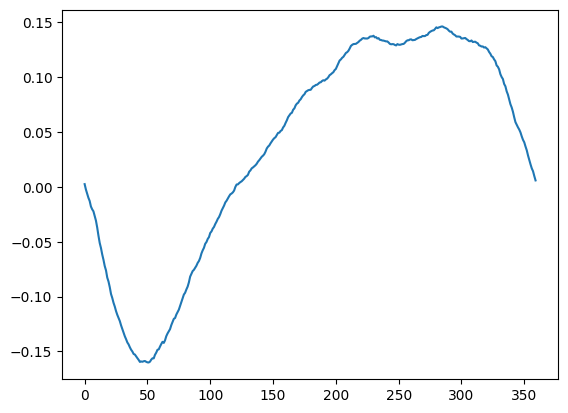

In [26]:
_x = np.zeros((360,))
for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    _x += axion_evpa_1d_diffs_16phase_1(alpha)[0, :]
plt.plot(_x)

In [38]:
# diffs_axion_evpa_t_1d = np.zeros((16, EVPA_fit_result_1d.shape[1]))
# diffs_axion_evpa_std_t_1d = np.zeros((16, EVPA_fit_result_1d.shape[1]))

# A_data_list_1d = deepcopy(EVPA_fit_result_1d[:, :, 0])
# A_data_list_1d[A_data_list_1d == 0] = np.nan
# phi0_data_list_1d = deepcopy(EVPA_fit_result_1d[:, :, 1])
# phi0_data_list_1d[phi0_data_list_1d == 0] = np.nan

In [39]:
# 2min
# A_params_1d=np.apply_along_axis(fit_gaussian_params,0,A_data_list_1d,rm_nan=True)
# phi0_params_1d=np.apply_along_axis(fit_gaussian_params,0,phi0_data_list_1d,rm_nan=True) # change it

In [40]:
# # np.save("A_params_1d",A_params_1d)
# # np.save("phi0_params_1d",phi0_params_1d)
# A_params_1d = np.load("A_params_1d.npy")  # amplitude, mean, stddev
# phi0_params_1d = np.load("phi0_params_1d.npy")

In [41]:
# amp_1d = EVPA_fit_result_1d[51, :, 0]
# phi0_1d = EVPA_fit_result_1d[51, :, 1]
# for i in range(extra_phase.shape[0]):
#     ep = extra_phase[i]
#     diffs_axion_evpa_t_1d[i] = (
#         constant1_axion * amp_1d * np.sin(ep + phi0_1d)
#     )  # *gagg[g]
#     diffs_axion_evpa_std_t_1d[i] = np.sqrt(
#         np.power(constant1_axion * np.sin(ep + phi0_1d) * A_params_1d[2], 2)
#         + np.power(
#             constant1_axion * amp_1d * np.cos(ep + phi0_1d) * phi0_params_1d[2], 2
#         )
#     )
# diffs_axion_evpa_1d = np.mean(diffs_axion_evpa_t_1d, axis=0)  # rad
# diffs_axion_evpa_std_1d = np.mean(diffs_axion_evpa_std_t_1d, axis=0)  # rad

# EXPERIMENT


In [27]:
import pickle
import numpy as np
import matplotlib
import os
import argparse
import numpy as np
from copy import deepcopy
from scipy.interpolate import griddata, interp2d
from scipy import integrate, optimize
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter


def plotting_script(xarray, yarray, name="test"):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 9))
    ax.set_xscale("log")
    ax2 = ax.twiny()
    ax2.set_xscale("log")
    ax2.set_ylim(-2, 6)
    ax.set_yticks([-2, -1, 0, 1, 2, 3, 4, 5, 6])
    ax.set_yticklabels(["-2", "-1", "0", "1", "2", "3", "4", "5", "6"], size=20)
    ax.set_ylabel(r"$\log_{10}(c)$", size=30)
    ax2.set_xticks([0.1, 0.45])
    ax2.set_xticklabels(["0.1", "0.45"], size=20)
    ax2.set_xlabel(r"$ \alpha $", size=30)
    ax2.set_xlim(0.0486495, 4.86495)
    ax.set_xlim(1e-19, 1e-21)
    ax.set_xticks([1e-21, 1e-20, 1e-19])
    ax.set_xticklabels(["-21", "-20", "-19"], size=20)
    ax.set_xlabel(r"$\log_{10}(m_a/\mathrm{eV})$", size=30)
    ax2.plot(xarray, yarray, "black")
    ax2.plot([np.max(xarray), np.max(xarray)], [yarray[-1], 6], "black")
    ax2.plot([np.min(xarray), np.min(xarray)], [yarray[0], 6], "black")

    xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
    ax2.fill_between(xarray, yarray, 6, ls="-", lw=2, fc=xcolor[0], alpha=1)
    plt.savefig(f"M_all/new_static/{name}.pdf", dpi=600)


def get_inv(M):
    u, s, v = np.linalg.svd(M)
    return np.dot(u / s, u.T)

# Final


In [28]:
import scipy.stats as stats

In [29]:
def vonmises_mean(d1evpaarr):
    # d1evpaarr is from -0.5pi to 0.5pi
    kappa_fit, mu_fit, _ = stats.vonmises.fit(d1evpaarr * 2)  # 只拟合 kappa 和 mu
    return mu_fit / 2

In [30]:
def topset_rank(data_cor, data_std):
    sum_of_pixels = np.zeros(1572)
    for i in range(4):
        rmnan_times = np.nan_to_num(data_cor[i] / data_std[i].reshape(4096, 1), nan=0)
        sum_of_pixels += np.sum(
            ((rmnan_times)[np.where(condition2to9.reshape(4096))]) ** 2, axis=0
        )
    return sum_of_pixels

In [31]:
theta_mean = []
theta_std = []
P_mean = []
I_mean = []
theta_cor = []
badset = []
theta_data_vonmises_list = []
resolution = 64
xy_coord = [(i, j) for i in range(resolution) for j in range(resolution)]


num = 0
data_cor_list = []
for day in [95, 96, 100, 101]:
    with np.load(f"./EHT-Imaging/data_out/{day}.npz") as data:
        theta_mean.append(data["arr_0"])  # rad
        theta_std.append(data["arr_1"])  # rad
        P_mean.append(data["arr_2"] * 6.54737e12)  # ?这个哪来的
        # I_mean.append(data['arr_3']*6.54737E12)
        # P_mean.append(data['arr_2'])

    All_data = np.load(f"./EHT-Imaging/data_out/{day}_all_data.npy")
    theta_data = 0.5 * np.arctan2(All_data[:, :, :, 2], All_data[:, :, :, 1])  # rad
    theta_vonmises_mean = np.apply_along_axis(vonmises_mean, 0, theta_data)
    theta_data_vonmises_list.append(
        CircleCalc.circle_sub_evpa(theta_data, theta_vonmises_mean)
        + theta_vonmises_mean
    )

    theta_data = (
        CircleCalc.circle_sub_evpa(theta_data, theta_mean[num]) + theta_mean[num]
    )
    # theta_data=theta_data*180./np.pi # degree

    data_cor = np.zeros((64 * 64, All_data.shape[0]))
    for x in range(len(xy_coord)):
        i, j = xy_coord[x]
        if (
            theta_mean[num][i][j] == 0
            and theta_std[num][i][j] == 0
            or np.isnan(theta_mean[num][i][j])
            or np.isnan(theta_std[num][i][j])
        ):
            badset.append(i * resolution + j)
        # data_cor[x] = (theta_data[i][j]-theta_mean[num][i][j])
        if np.isfinite(theta_mean[num][i][j]):
            pass
        data_cor[x] = CircleCalc.circle_sub_evpa(
            theta_data[:, i, j], theta_mean[num][i, j]
        )
    data_cor_list.append(data_cor)
    num += 1

sum_of_pixels = topset_rank(data_cor_list, theta_std)

for num in range(4):

    # cor_data = np.dot(data_cor_list[num],data_cor_list[num].T)/All_data.shape[0]
    cor_data = (
        np.dot(
            data_cor_list[num][:, np.argsort(sum_of_pixels)[:786]],
            data_cor_list[num][:, np.argsort(sum_of_pixels)[:786]].T,
        )
        / 786
    )

    theta_cor.append(cor_data)

/tmp/ipykernel_46548/1848349312.py:4: RuntimeWarning: invalid value encountered in divide
  rmnan_times = np.nan_to_num(data_cor[i] / data_std[i].reshape(4096, 1), nan=0)


In [47]:
# def gaussian2(x, *param):
#     mean = param[0]
#     sigma = param[1]
#     amplitude = param[2]
#     return (
#         amplitude
#         / np.sqrt(2.0 * np.pi * sigma * sigma)
#         * np.exp(-np.power(x - mean, 2.0) / 2.0 / sigma / sigma)
#     )

In [48]:
# def fit_gaussian2(d1evpaarr, bins_i=4):
#     counts, bins = np.histogram(d1evpaarr, bins=10 * bins_i)  # 10*(4)
#     # counts,bins =re_loc(counts,bins)
#     xarray = np.array([(bins[i] + bins[i + 1]) / 2 for i in range(len(bins) - 1)])
#     try:
#         popt, pcov = optimize.curve_fit(
#             gaussian2, xarray, counts, p0=[vonmises_mean(d1evpaarr), 1, 786]
#         )  # ,maxfev=50000,gtol=1e-10
#     except Exception as e:
#         print(f"badfit, error", e)
#         return np.array([np.nan, np.nan, np.nan])
#     if abs(pcov[0][0]) > abs(popt[0]) or abs(pcov[1][1]) > abs(popt[1]):
#         print(f"badfit")
#         return np.array([np.nan, np.nan, np.nan])
#     else:
#         return np.array([popt[0], np.abs(popt[1]), popt[2]])

In [32]:
std_786 = []
mean_786 = []
theta_cor = []
num_786 = 786
for num in range(4):
    print(num)
    theta_data_786 = (
        theta_data_vonmises_list[num]
        .reshape(1572, 4096)
        .T[:, np.argsort(sum_of_pixels)[:num_786]]
    )
    tmpres = np.apply_along_axis(
        fit_gaussian2,
        1,
        theta_data_786,
        plot_failed=False,
        angle=True,
        lower_bound=-np.pi / 2,
        upper_bound=np.pi / 2,
        threshold=0.2,
    )
    mean_786.append(tmpres[:, 0])
    std_786.append(tmpres[:, 1])
    cor_data = CircleCalc.circle_sub_evpa(theta_data_786.T, tmpres[:, 0]).T
    theta_cor.append(np.dot(cor_data, cor_data.T) / num_786)

0
badfit, 0.2282630907378714, 0.9644709521365301 * 0.2
badfit, 0.25652412473515873, 0.9870457481666637 * 0.2
badfit, 0.23218104561388728, 1.012905221559464 * 0.2
badfit, 0.2194750866677592, 1.008039334365171 * 0.2
badfit, 0.24558918593121007, 1.042307466392261 * 0.2
badfit, 0.23824545889424328, 1.059631918352125 * 0.2


/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:65: RuntimeWarning: divide by zero encountered in scalar divide
  amplitude
/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:67: RuntimeWarning: divide by zero encountered in divide
  * np.exp(-np.power(x - mean, 2.0) / 2.0 / sigma / sigma)
/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:65: RuntimeWarning: invalid value encountered in multiply
  amplitude
/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:214: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = optimize.curve_fit(


badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf, 0.0 * 0.2
badfit, inf

In [50]:
np.isnan(std_786[2]).sum()

np.int64(496)

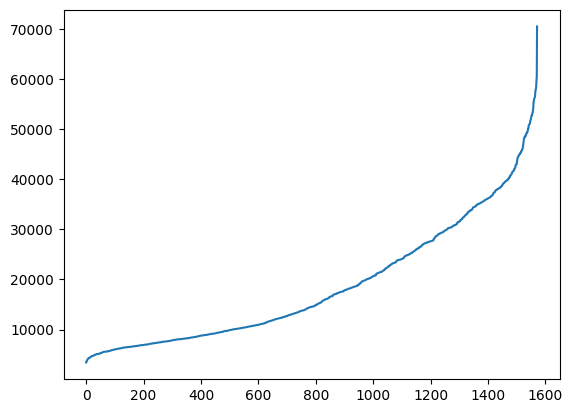

In [51]:
plt.plot(sum_of_pixels[np.argsort(sum_of_pixels)])

In [52]:
theta_mean[2].reshape(-1)[45 * 64 + 31]

np.float64(-1.043334284371979)

In [53]:
mean_786[2][45 * 64 + 31]

np.float64(-1.040822344499646)

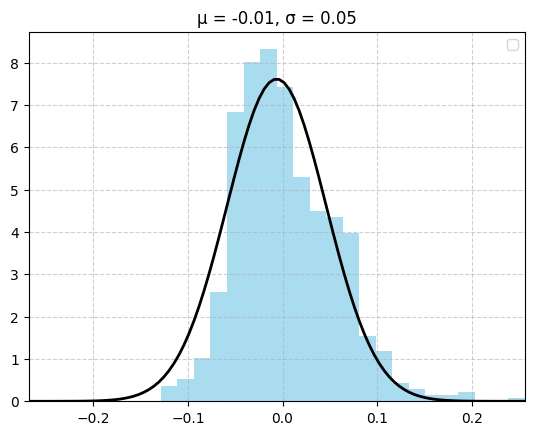

In [54]:
mean, sigma = fit_gaussian2(
    data_cor_list[3][45 * 64 + 31][np.argsort(sum_of_pixels)[:786]],
    bins=30,
    threshold=0.2,
)
plot_gaussian(
    data_cor_list[3][45 * 64 + 31][np.argsort(sum_of_pixels)[:786]],
    bins=30,
    # plot_range=(-np.pi / 2, np.pi / 2),
    mean=mean,
    sigma=sigma,
)

In [37]:
def fastxtMinvx(x, M):
    L = cho_factor(M, lower=True)
    y = cho_solve(L, x)
    return np.dot(x, y)

In [56]:
# f_axion_norm(0.1, R_photon_ring) / f_axion_norm(0.45, R_photon_ring)

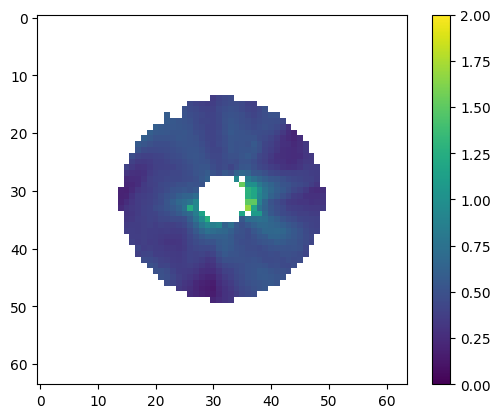

In [57]:
plt.imshow(np.mean(axion_evpa_diffs_std_16phase[0.3], axis=0) / np.pi * 180)
plt.colorbar()
plt.clim(0, 2)

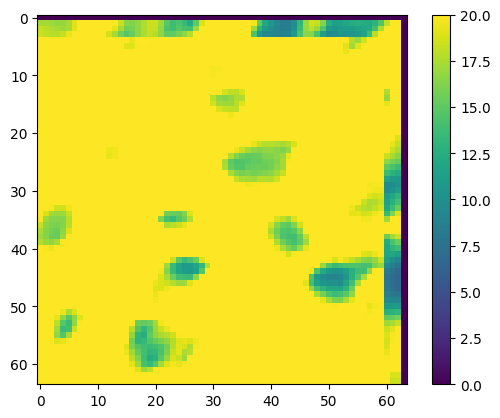

In [58]:
plt.imshow(
    np.sqrt(theta_std[3] * theta_std[3] + theta_std[2] * theta_std[2]) / np.pi * 180
)
plt.colorbar()
plt.clim(0, 20)

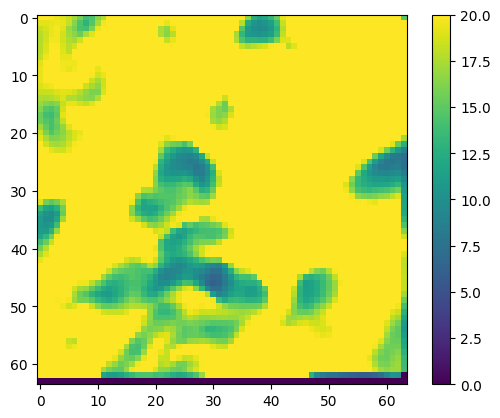

In [59]:
plt.imshow(
    np.sqrt(theta_std[0] * theta_std[0] + theta_std[1] * theta_std[1]) / np.pi * 180
)
plt.colorbar()
plt.clim(0, 20)

In [ ]:
if not os.path.exists("Results/figure"):
    os.makedirs("Results/figure")
if not os.path.exists("Results/data"):
    os.makedirs("Results/data")

/tmp/ipykernel_681590/3984944986.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(x_range, fit_curve, 'r-', label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "+f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",color='brown')


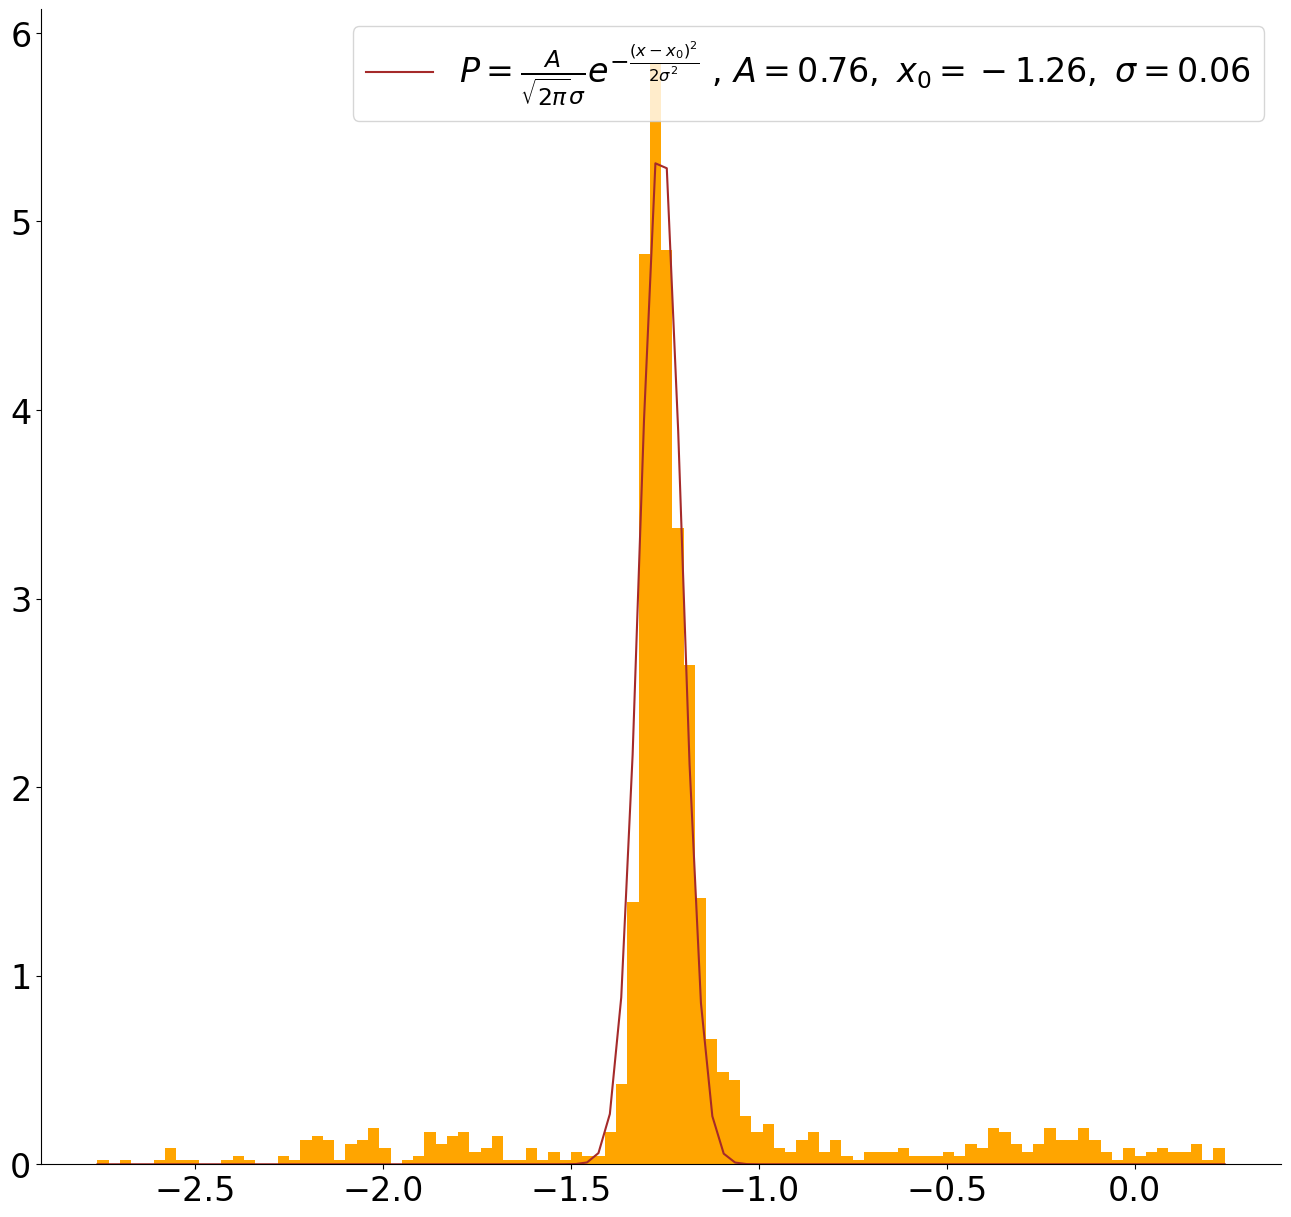

(array([ 0.76118142, -1.26049871,  0.05522948]),
 array([[ 4.06529984e-04, -2.63238052e-15,  1.96646288e-05],
        [-2.63238052e-15,  2.85364635e-06, -4.86296409e-13],
        [ 1.96646288e-05, -4.86296409e-13,  2.85364645e-06]]))

In [ ]:
# plot_gaussian1(
#     theta_data_vonmises_list[num].reshape(1572, 4096).T[45 * 64 + 31],
#     bins=100,
#     plot_range=(-1.5 - 1.26, 1.5 - 1.26),
#     plot=True,
#     initial_guess=[1, 0, 1],
#     rm_nan=True,
#     figsize=(16, 15),
# )

/tmp/ipykernel_681590/3984944986.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(x_range, fit_curve, 'r-', label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "+f"$A={params[0]:.2f},\ x_0={params[1]:.2f},\ \sigma={params[2]:.2f}$",color='brown')


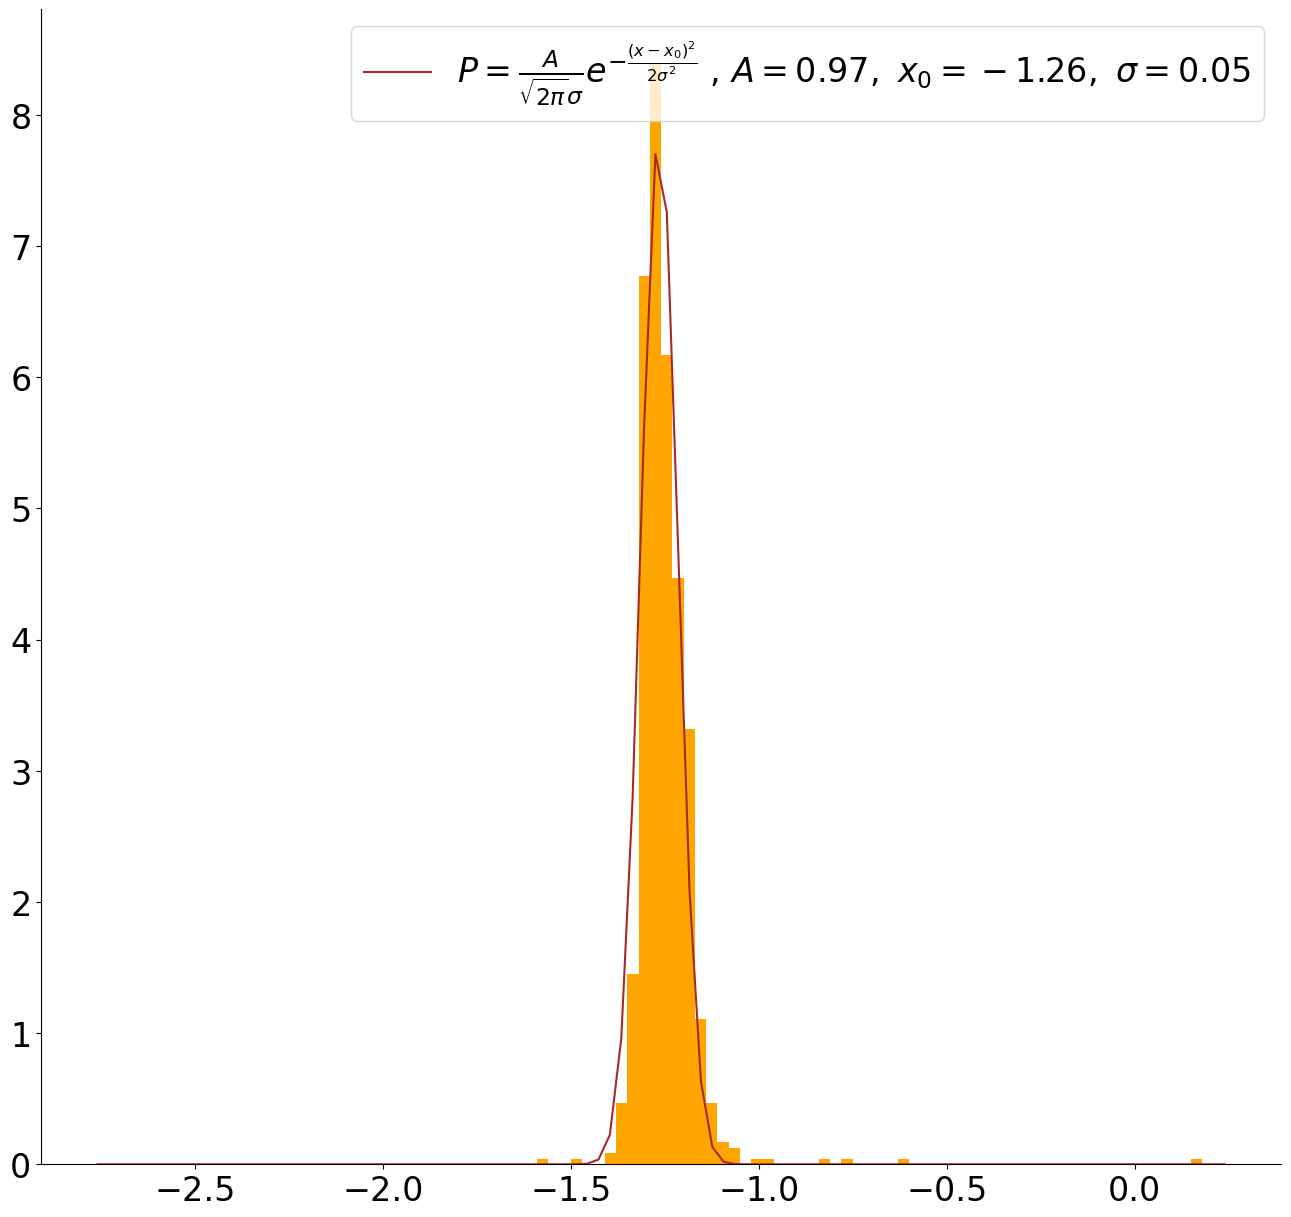

(array([ 0.97383476, -1.2647543 ,  0.04933179]),
 array([[ 7.14082722e-04,  8.73704720e-14,  2.41155243e-05],
        [ 8.73704720e-14,  2.44324005e-06, -4.56040097e-13],
        [ 2.41155243e-05, -4.56040097e-13,  2.44324011e-06]]))

In [ ]:
# plot_gaussian1(
#     theta_data_786[45 * 64 + 31],
#     bins=100,
#     plot_range=(-1.5 - 1.26, 1.5 - 1.26),
#     plot=True,
#     initial_guess=[1, 0, 1],
#     rm_nan=True,
#     figsize=(16, 15),
# )

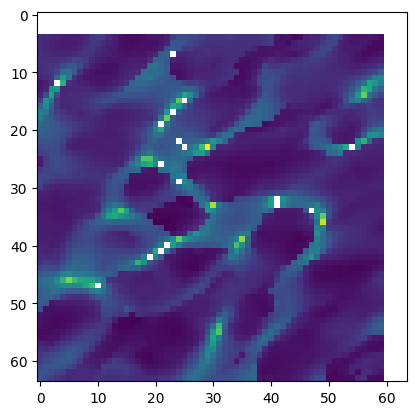

In [ ]:
# plt.imshow(std_786[2].reshape(64, 64) / np.pi * 180)

In [ ]:
# (
#     np.sqrt(np.diag(theta_cor[0] + theta_cor[1] + theta_cor[2] + theta_cor[3]))
#     / np.sqrt(std_786[0] ** 2 + std_786[1] ** 2 + std_786[2] ** 2 + std_786[3] ** 2)
# )[45 * 64 + 31]

np.float64(1.651416351737656)

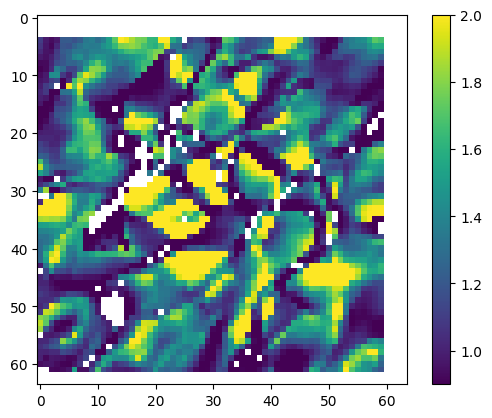

In [ ]:
# plt.imshow(
#     (
#         np.sqrt(np.diag(theta_cor[0] + theta_cor[1] + theta_cor[2] + theta_cor[3]))
#         / np.sqrt(std_786[0] ** 2 + std_786[1] ** 2 + std_786[2] ** 2 + std_786[3] ** 2)
#     ).reshape(64, 64)
# )
# plt.colorbar()
# plt.clim(0.9, 2)

In [ ]:
# np.std(theta_data_vonmises_list[num].reshape(1572, 4096).T[45 * 64 + 31])

np.float64(0.398691961449752)

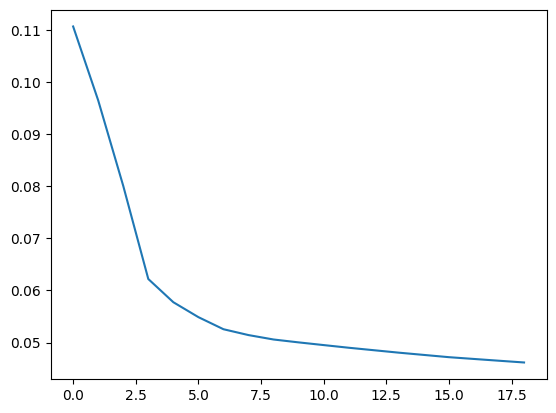

In [ ]:
# plt.plot([np.std(np.sort(theta_data_786[45 * 64 + 31])[de:-de]) for de in range(1, 20)])

In [ ]:
np.std(theta_data_786[45 * 64 + 31])

np.float64(0.1239376663120224)

In [42]:
def get_final_cut(mode="cor_grmhd"):
    # mode: "std", "cor", "cor_grmhd"
    # Delta_theta = [CircleCalc.circle_sub_evpa(theta_mean[1],theta_mean[0]).flatten(),CircleCalc.circle_sub_evpa(theta_mean[3],theta_mean[2]).flatten()] # evpasub
    Delta_theta = [
        CircleCalc.circle_sub_evpa(mean_786[1], mean_786[0]),
        CircleCalc.circle_sub_evpa(mean_786[3], mean_786[2]),
    ]  # evpasub, 但是我们不用
    # Delta_theta = [np.zeros(resolution*resolution),np.zeros(resolution*resolution)]

    # Delta_std =[np.reshape(np.sqrt(theta_std[1]*theta_std[1]+theta_std[0]*theta_std[0]),4096),np.reshape(np.sqrt(theta_std[3]*theta_std[3]+theta_std[2]*theta_std[2]),4096)]
    Delta_std = [
        np.sqrt(std_786[1] * std_786[1] + std_786[0] * std_786[0]),
        np.sqrt(std_786[3] * std_786[3] + std_786[2] * std_786[2]),
    ]
    cor_std = np.asarray([(theta_cor[1] + theta_cor[0]), (theta_cor[3] + theta_cor[2])])
    # cor_std = [theta_cor[1],theta_cor[2]]
    # print(theta_cor[1][1550][1500])

    # generate badset
    print("generating badset...")
    badset_with_large_delta = []  # deepcopy(badset)
    _tmp_axion_evpa_diffs_16phase_ = np.zeros((64, 64))
    for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
        _tmp_axion_evpa_diffs_16phase_ += np.sum(
            axion_evpa_diffs_16phase_1(alpha), axis=0
        )
        _tmp_axion_evpa_diffs_16phase_ += np.sum(
            axion_evpa_diffs_16phase_2(alpha), axis=0
        )
        _tmp_axion_evpa_diffs_16phase_ += np.sum(
            axion_evpa_diffs_std_16phase(alpha), axis=0
        )  # just for finding bad pixels
    for l in range(4):
        for i in range(resolution):
            for j in range(resolution):
                # if theta_mean[l][i][j] == 0 and theta_std[l][i][j] == 0:
                if (
                    mean_786[l][i * resolution + j] == 0
                    and std_786[l][i * resolution + j] == 0
                    or np.isnan(mean_786[l][i * resolution + j])
                    or np.isnan(std_786[l][i * resolution + j])
                ):
                    badset_with_large_delta.append(i * resolution + j)

                if condition2to9[i, j]:
                    if np.isnan(_tmp_axion_evpa_diffs_16phase_[i, j]):
                        # pass
                        # for lll in range(16):
                        #     diffs_axion_evpa_std_t[lll][i, j] = 1 / 2 / np.pi  # caution
                        #     diffs_axion_evpa_std[i, j] = 1 / 2 / np.pi  # caution
                        badset_with_large_delta.append(i * resolution + j)
                        # if i <5.5 or j <1.5:
                        #     badset.append(i*resolution+j)
                else:
                    badset_with_large_delta.append(i * resolution + j)
            # max_delta_theta=10
            # if Delta_theta[0][i*resolution+j]>max_delta_theta or Delta_theta[1][i*resolution+j]>max_delta_theta or Delta_theta[0][i*resolution+j]<-max_delta_theta or Delta_theta[1][i*resolution+j]<-max_delta_theta:
            #     badset_with_large_delta.append(i*resolution+j)
    if mode == "std":
        for i in range(4096):
            if np.isnan(Delta_std[0][i]) or np.isnan(Delta_std[1][i]):
                badset_with_large_delta.append(i)

    badset_with_large_delta = list(set(badset_with_large_delta))
    print(len(badset_with_large_delta))
    # end generate badset
    print("start calculating final_cut...")

    def getrange():
        # return [10, 15, 20, 25, 30, 35, 40, 44]
        return range(10, 45, 1)

    g_res = 40
    final_cut = [0 for alpha in getrange()]
    # temp_sig = []
    for idx, alpha in enumerate(getrange()):
        tbadset = deepcopy(badset_with_large_delta)
        goodset = list(range(resolution * resolution))
        # c = 0.005

        # if omega > 40:
        #     pass
        omega = _omega(alpha / 100)
        print(omega)
        # Fit_result = np.load(
        #     f"GRMHD/data_in/different_omega/{alpha/100}/EVPA_result.npy"
        # )
        # for x in range(len(xy_coord)):
        #     i = int(np.floor(x / 64))
        #     j = x % 64

        #     # * Change P_mean< : 0E9: full image.    0.1E9: 600 pixels.    0.5E9:    150 pixels.            0.9E9: 50 pixels.
        #     # dynamic_cut = 0.15*np.max(I_mean)
        #     dynamic_cut = 0.1e9
        #     if P_mean[1][i][j] < dynamic_cut:
        #         tbadset.append(x)
        #     # if (i-32)*(i-32)+(j-32)*(j-32)>16*16:
        #     #     tbadset.append(x)
        #     if Fit_result[i][j][0] == -3 and Fit_result[i][j][1] == -3:
        #         tbadset.append(x)
        tbadset = np.unique(tbadset)
        tbadset.sort()
        for x in range(len(tbadset)):
            goodset.remove(tbadset[x])
        goodsetrow = np.asarray([[x for y in goodset] for x in goodset])
        goodsetcol = np.asarray([goodset for x in goodset])
        # print(np.mean([((Fit_result[:,:,0])[x//64][x%64]/theta_std[0][x//64][x%64])**2 for x in goodset]))
        phi_0 = np.linspace(0, 2 * np.pi, 16)
        gagg = np.logspace(np.log10(1 / 137.0), 2, g_res)
        prgagg = np.zeros(g_res)
        Delta_theta_theory = [
            [np.zeros((resolution, resolution)), np.zeros((resolution, resolution))]
            for i in range(16)
        ]
        llh_axion = np.zeros((g_res, 16))
        llh_axion_g = np.zeros(g_res)
        # llh_astro = np.zeros((g_res, 16))
        # llh_astro_g = np.zeros(16)
        print(np.shape(np.asarray(cor_std[0][goodsetrow, goodsetcol])))
        # M_all=[np.asarray(cor_std)+cor_grmhd+np.diag(np.power(np.reshape(diffs_axion_evpa_std_t[i],4096),2)) for i in range(16) ]
        # M_inv = [[get_inv(np.asarray(M_all[i][0][goodsetrow,goodsetcol])),get_inv(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))] for i in range(16)]
        # np.save(f'M_inv_{omega}',M_inv)
        # np.save(f'cor_std',cor_std)
        # print(f"{np.max(M_inv)},{np.min(M_inv)}")
        # print(f"{np.max(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))},{np.min(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))}")

        # amp = np.asarray(Fit_result[:, :, 0])
        # print(amp.mean(), amp.max())
        # ini_phase = np.asarray(Fit_result[:, :, 1])
        # offset = np.asarray(Fit_result[:, :, 2])  # /180*np.pi

        if mode == "std":
            cor_std_good = np.asarray(
                [np.diag(Delta_std[0]) ** 2, np.diag(Delta_std[1]) ** 2]
            )[:, goodsetrow, goodsetcol]
        else:
            cor_std_good = cor_std[:, goodsetrow, goodsetcol]
        if mode == "cor_grmhd":
            cor_grmhd_good = cor_grmhd[goodsetrow, goodsetcol]
            tmpCorAxion = [
                np.diag(
                    np.power(
                        np.reshape(
                            axion_evpa_diffs_std_16phase(alpha / 100)[i],
                            4096,
                        ),
                        2,
                    )
                )[goodsetrow, goodsetcol]
                for i in range(16)
            ]
        else:
            cor_grmhd_good = 0
            tmpCorAxion = [0 for i in range(16)]
        for g in range(g_res):
            # print(g)
            M_all = [
                cor_std_good + cor_grmhd_good + tmpCorAxion[i] * (gagg[g]) ** 2
                for i in range(16)
            ]
            # M_inv = [[get_inv(M_all[i][0])]*2 for i in range(16)]

            for l in range(16):
                # Delta_theta_theory[l][0] = 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(phi_0[l]+ini_phase)/0.1*gagg[g] #?
                # Delta_theta_theory[l][1] = 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(phi_0[l]+0.112411*omega/2*24*5+ini_phase)/0.1*gagg[g]
                Delta_theta_theory[l][0] = (
                    axion_evpa_diffs_16phase_1(alpha / 100)[l] * gagg[g]
                )
                # Delta_theta_theory[l][0] = (
                #     2
                #     * amp
                #     * np.sin(0.112411 * omega / 2 * 24)
                #     * np.sin(0.112411 * omega / 2 * 6)
                #     / (0.112411 * omega / 2 * 6)
                #     * np.sin(phi_0[l] + ini_phase)
                #     / 0.5
                #     * gagg[g]
                # )  # ?
                Delta_theta_theory[l][1] = (
                    axion_evpa_diffs_16phase_2(alpha / 100)[l] * gagg[g]
                )
                # Delta_theta_theory[l][1] = (
                #     2
                #     * amp
                #     * np.sin(0.112411 * omega / 2 * 24)
                #     * np.sin(0.112411 * omega / 2 * 6)
                #     / (0.112411 * omega / 2 * 6)
                #     * np.sin(phi_0[l] + 0.112411 * omega / 2 * 24 * 5 + ini_phase)
                #     / 0.5
                #     * gagg[g]
                # )

                Delta_theta_theory[l][0] = np.reshape(Delta_theta_theory[l][0], 4096)
                Delta_theta_theory[l][1] = np.reshape(Delta_theta_theory[l][1], 4096)

                for k in range(2):
                    x_diff = np.matrix(
                        (Delta_theta_theory[l][k] - Delta_theta[k] * 0)[goodset]
                    )

                    # * Calculate with cor_std.
                    # llh_axion[g][l] +=np.exp(-(np.array(np.dot(x_diff,np.dot(M_inv[l][k],x_diff.T)))[0][0])/2.)
                    llh_axion[g][l] += np.exp(
                        -fastxtMinvx(np.asarray(x_diff)[0], M_all[l][k]) / 2.0
                    )
                    # llh_axion[g][l] +=np.exp(0)

                    # * Calculate with std.
                    # llh_axion[g][l] +=np.exp(-np.sum(x_diff*x_diff.T/(2*Delta_std[k][goodset]*Delta_std[k][goodset])))

            llh_axion_g = np.sum(llh_axion, axis=1) / 16
            # llh_astro_g = np.sum(llh_astro,axis=1)/160
            for x in range(g_res):
                if x >= g:
                    prgagg[x] += llh_axion_g[g] / g_res
        g = 0
        while prgagg[g] < prgagg[g_res - 1] * 0.95:
            g += 1
        g -= 1
        # print(prgagg[-2])
        final_cut[idx] = (prgagg[g_res - 1] * 0.95 - prgagg[g]) / (
            prgagg[g + 1] - prgagg[g]
        ) * (np.log10(gagg[g + 1]) - np.log10(gagg[g])) + np.log10(gagg[g])
        print(f"{alpha-10} is done!", final_cut[idx])

    plt.plot([alpha * 0.01 for alpha in getrange()], final_cut, "s-")
    name = mode
    plt.savefig(f"Results/figure/{name}.pdf")
    plotting_script([alpha * 0.01 for alpha in getrange()], final_cut, name)
    np.savez(
        f"Results/data/{name}",
        alphas=[alpha * 0.01 for alpha in getrange()],
        cuts=final_cut,
    )
    return final_cut

In [47]:
list(EVPA_cos_fit_result.keys())

[0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]

generating badset...
3215
start calculating final_cut...
0.09996875
(881, 881)
0 is done! 0.6710156892104657
0.10995840625
(881, 881)
1 is done! 0.5504442573493618
0.119946
(881, 881)
2 is done! 0.45079645076287445
0.12993134375
(881, 881)
3 is done! 0.3635810383481158
0.13991425000000002
(881, 881)
4 is done! 0.2814847497553278
0.14989453125
(881, 881)
5 is done! 0.2097491640911806
0.159872
(881, 881)
6 is done! 0.15020231467679038
0.16984646875
(881, 881)
7 is done! 0.07870301060174596
0.17981775
(881, 881)
8 is done! 0.018633573519228668
0.18978565625
(881, 881)
9 is done! -0.032582887749871794
0.19975
(881, 881)
10 is done! -0.09087010361297296
0.20971059374999998
(881, 881)
11 is done! -0.13637436257169128
0.21966725
(881, 881)
12 is done! -0.18896278801904542
0.22961978125000002
(881, 881)
13 is done! -0.2333455754654673
0.23956799999999998
(881, 881)
14 is done! -0.26354164291015925
0.24951171875
(881, 881)
15 is done! -0.32010517665012694
0.25945075
(881, 881)
16 is done! -0.34

<Figure size 640x480 with 0 Axes>

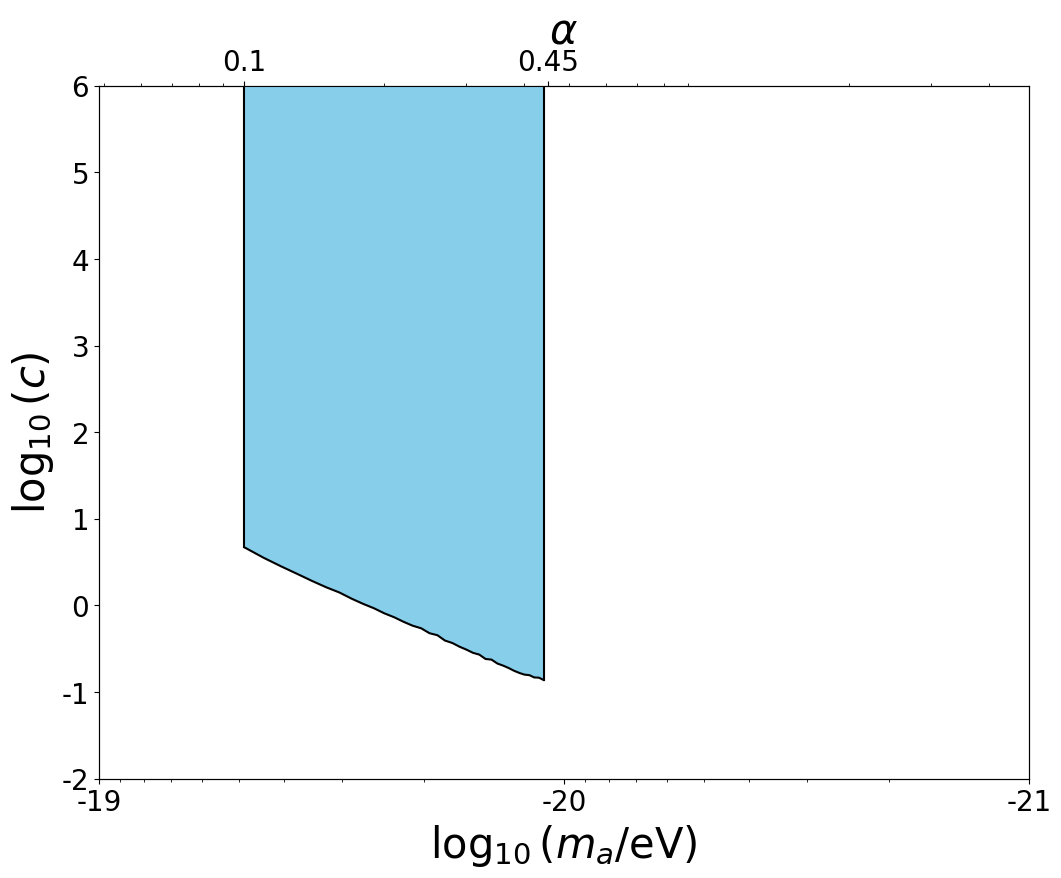

In [50]:
final_cut = get_final_cut(mode="std")

generating badset...
3215
start calculating final_cut...
0.09996875
(881, 881)
0 is done! 0.6710156892104657
0.10995840625
(881, 881)
1 is done! 1.2586003056850477
0.119946
(881, 881)
2 is done! 0.8084346618846147
0.12993134375
(881, 881)
3 is done! 0.5016745896162859
0.13991425000000002
(881, 881)
4 is done! 0.3306948281554975
0.14989453125
(881, 881)
5 is done! 0.2097491640911806
0.159872
(881, 881)
6 is done! 0.5814961268388532
0.16984646875
(881, 881)
7 is done! 0.6943402401913675
0.17981775
(881, 881)
8 is done! 0.2513790910110079
0.18978565625
(881, 881)
9 is done! 0.04472627530989826
0.19975
(881, 881)
10 is done! -0.09087010361297296
0.20971059374999998
(881, 881)
11 is done! 0.21786789062989315
0.21966725
(881, 881)
12 is done! 0.6408772478077156
0.22961978125000002
(881, 881)
13 is done! 0.05698607089502987
0.23956799999999998
(881, 881)
14 is done! -0.17325370971550597
0.24951171875
(881, 881)
15 is done! -0.32010517665012694
0.25945075
(881, 881)
16 is done! -0.034823504214

<Figure size 640x480 with 0 Axes>

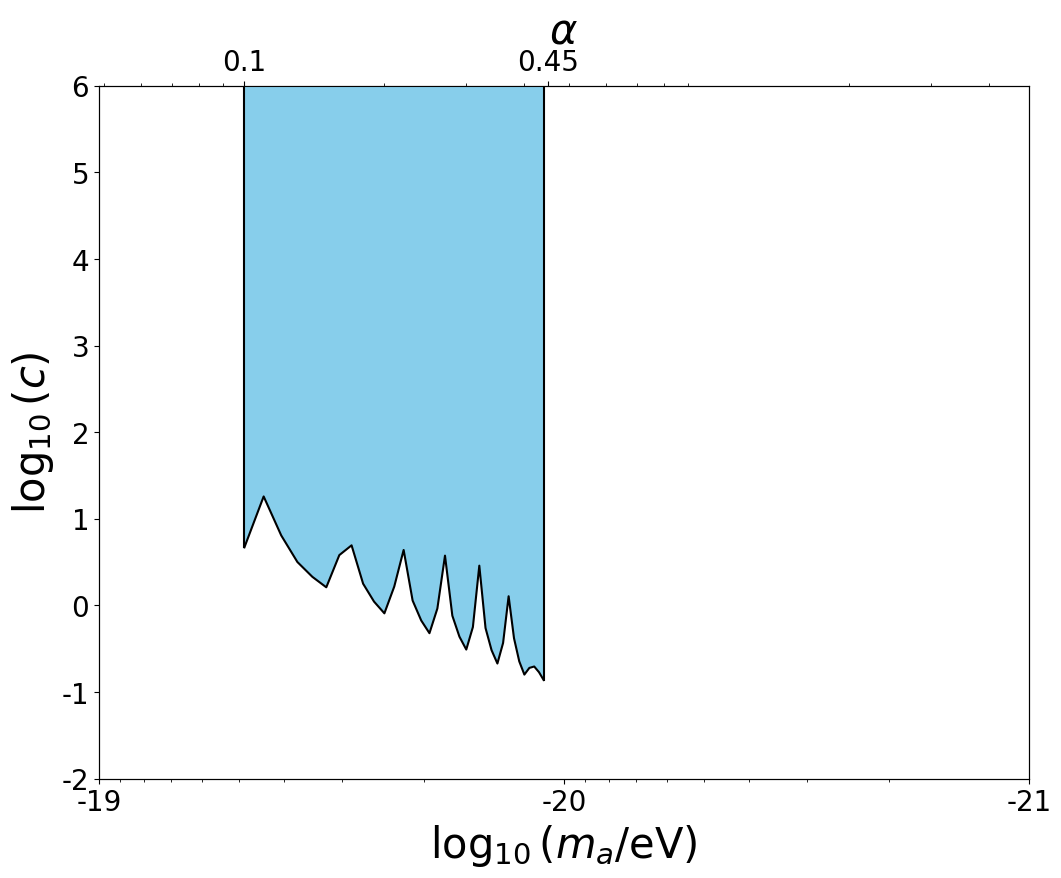

In [70]:
final_cut = get_final_cut(mode="std")

3215
0.09996875
(539, 539)
0.0014981062270165422 0.004769736328783366
0 is done! 1.1567978846219766
0.14989453125
(539, 539)
0.00282425442958796 0.009077855556346695
5 is done! 0.6943036799880776
0.19975
(539, 539)
0.004396868671631508 0.011136752374615283
10 is done! 0.38832790026471653
0.24951171875
(539, 539)
0.00592881622038441 0.01497145080899833
15 is done! 0.1613740628097336
0.29915625
(539, 539)
0.007153946276491862 0.02167596646979022
20 is done! -0.03296712956345638
0.34866015625
(539, 539)
0.007894285198117013 0.03643054821408905
25 is done! -0.19213223781016586
0.398
(539, 539)
0.008049860339355648 0.0550129350026117
30 is done! -0.32545192641558396
0.437338
(539, 539)
0.007633516459934814 0.06634598040038568
34 is done! -0.37971084041775804


<Figure size 640x480 with 0 Axes>

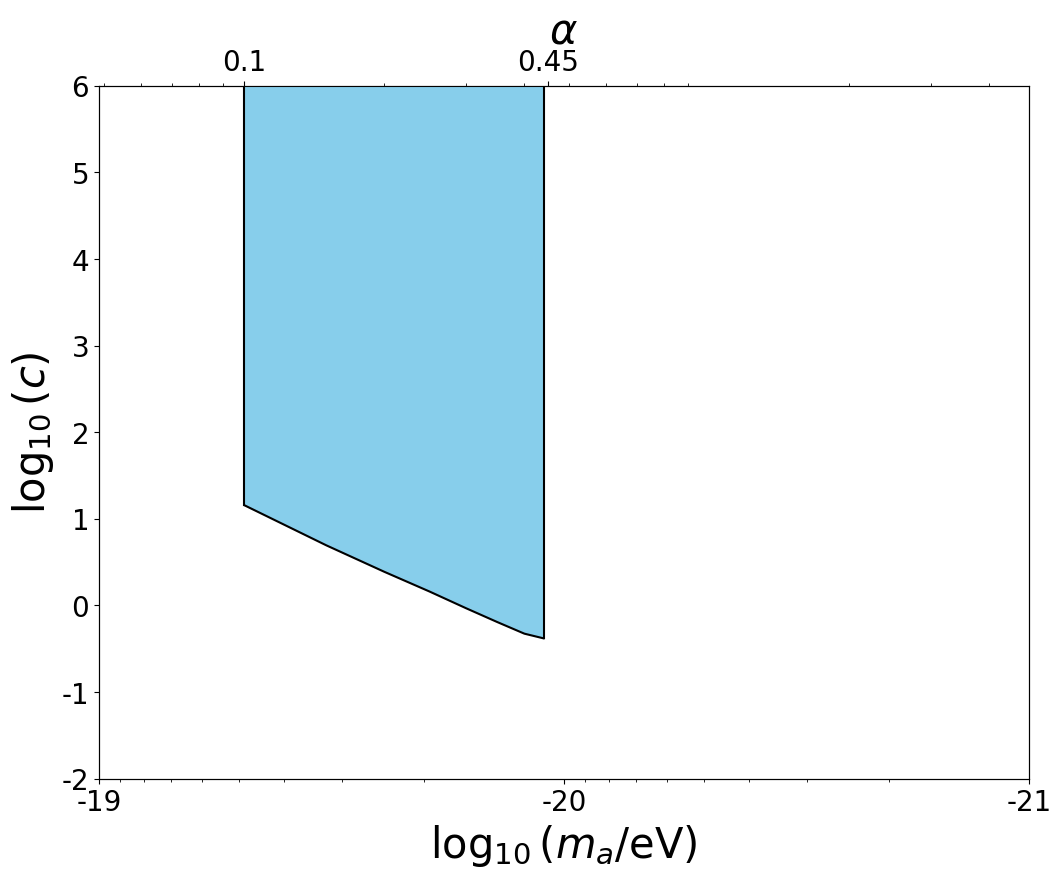

In [65]:
final_cut = get_final_cut(mode="cor_grmhd")

3215
0.09996875
(539, 539)
0.0014981062270165422 0.004769736328783366
0 is done! 1.1383941201093128
0.14989453125
(539, 539)
0.00282425442958796 0.009077855556346695
5 is done! 0.6768144267346189
0.19975
(539, 539)
0.004396868671631508 0.011136752374615283
10 is done! 0.3723334556407528
0.24951171875
(539, 539)
0.00592881622038441 0.01497145080899833
15 is done! 0.14527818960880093
0.29915625
(539, 539)
0.007153946276491862 0.02167596646979022
20 is done! -0.049300843967538394
0.34866015625
(539, 539)
0.007894285198117013 0.03643054821408905
25 is done! -0.212157408568441
0.398
(539, 539)
0.008049860339355648 0.0550129350026117
30 is done! -0.3442153555770682
0.437338
(539, 539)
0.007633516459934814 0.06634598040038568
34 is done! -0.39953032009117173


<Figure size 640x480 with 0 Axes>

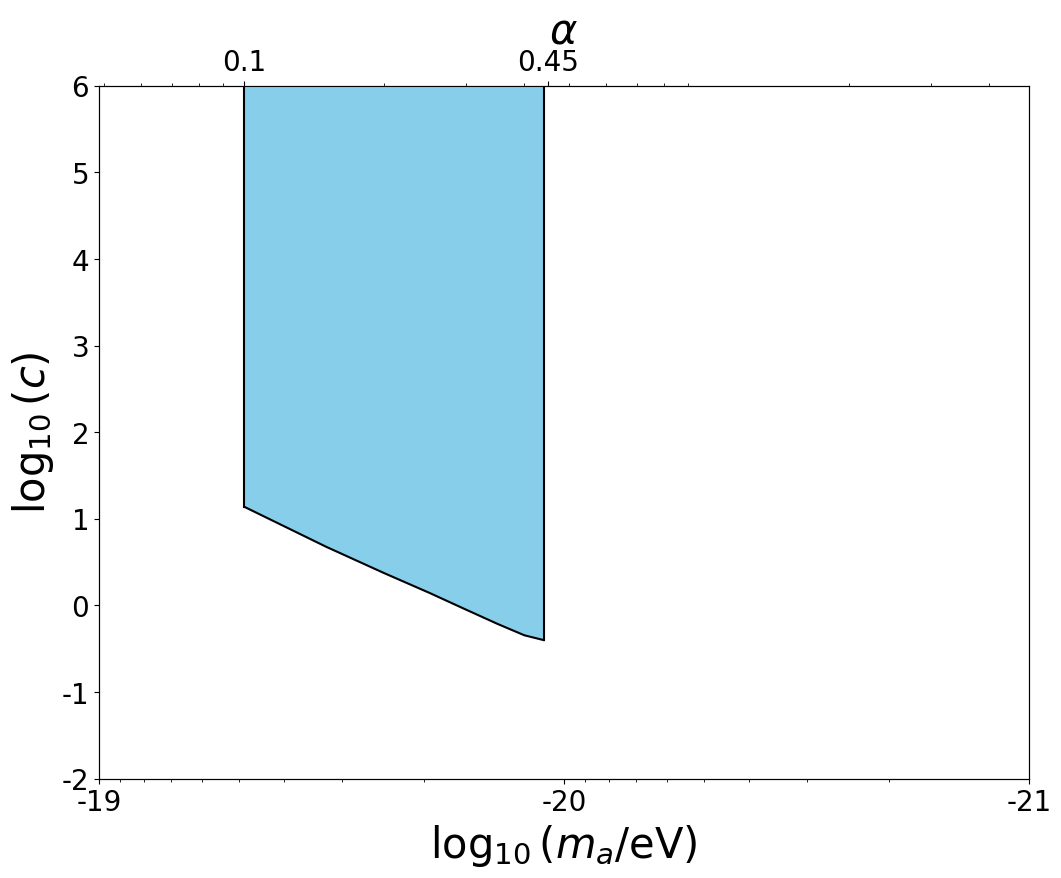

In [66]:
final_cut = get_final_cut(mode="cor")

0.1
(540, 540)
0.0014981062270165422 0.004769736328783366
0 is done!
0.11
(540, 540)
0.0017380764397918738 0.00562915915126139
1 is done!
0.12
(540, 540)
0.001989219365530126 0.00650955121197444
2 is done!
0.13
(540, 540)
0.0022525604589400203 0.007391635365240134
3 is done!
0.14
(540, 540)
0.002531826454408145 0.00826102741926068
4 is done!
0.15
(540, 540)
0.00282425442958796 0.009077855556346695
5 is done!
0.16
(540, 540)
0.003126091832086294 0.009799463396045307
6 is done!
0.17
(540, 540)
0.0034327347400857165 0.010377386558797483
7 is done!
0.18
(540, 540)
0.003753171236639048 0.01081195154707917
8 is done!
0.19
(540, 540)
0.004079850222465271 0.011060769797075312
9 is done!
0.2
(540, 540)
0.004396868671631508 0.011136752374615283
10 is done!
0.21
(540, 540)
0.004708562935053972 0.011932717994610285
11 is done!
0.22
(540, 540)
0.0049988736671895285 0.012646475271685853
12 is done!
0.23
(540, 540)
0.005288706110669394 0.013346436785094893
13 is done!
0.24
(540, 540)
0.00560437032396

<Figure size 640x480 with 0 Axes>

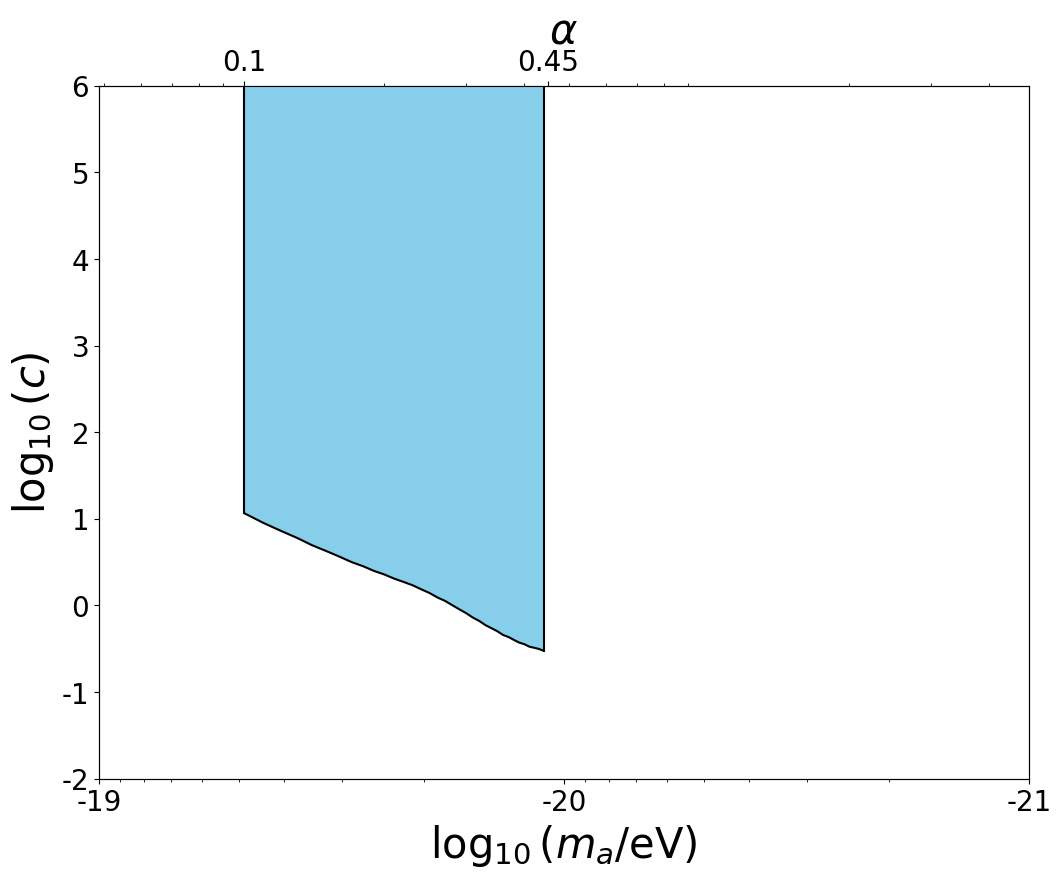

In [ ]:
final_cut = get_final_cut(mode="cor_grmhd")

# 1d


In [ ]:
import pickle
import numpy as np
import matplotlib
import os
import argparse
import numpy as np
from copy import deepcopy

from scipy.interpolate import griddata, interp2d
from scipy import integrate, optimize
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter


def plotting_script(xarray, yarray, name):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 9))
    ax.set_xscale("log")
    ax2 = ax.twiny()
    ax2.set_xscale("log")
    ax2.set_ylim(-2, 6)
    ax.set_yticks([-2, -1, 0, 1, 2, 3, 4, 5, 6])
    ax.set_yticklabels(["-2", "-1", "0", "1", "2", "3", "4", "5", "6"], size=20)
    ax.set_ylabel("$\log_{10}(c)$", size=30)
    ax2.set_xticks([0.1, 0.45])
    ax2.set_xticklabels(["0.1", "0.45"], size=20)
    ax2.set_xlabel(r"$ \alpha $", size=30)
    ax2.set_xlim(0.0486495, 4.86495)
    ax.set_xlim(1e-19, 1e-21)
    ax.set_xticks([1e-21, 1e-20, 1e-19])
    ax.set_xticklabels(["-21", "-20", "-19"], size=20)
    ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)
    ax2.plot(xarray, yarray, "black")
    ax2.plot([np.max(xarray), np.max(xarray)], [yarray[-1], 6], "black")
    ax2.plot([np.min(xarray), np.min(xarray)], [yarray[0], 6], "black")

    xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
    ax2.fill_between(xarray, yarray, 6, ls="-", lw=2, fc=xcolor[0], alpha=1)
    plt.savefig(f"new_static/{name}.pdf", dpi=600)


theta_mean = []
theta_std = []
theta_cor = []
badset = []
resolution = 360

num = 0
for day in [95, 96, 100, 101]:
    # with np.load(f'./EHT-Imaging/{day}_1d.npz') as data:
    #     theta_mean.append(data['arr_0'])
    #     theta_std.append(data['arr_1'])

    theta_data = np.load(f"./EHT-Imaging/data_out/{day}_EVPA_1d.npy")
    # _tmp_sub = CircleCalc.circle_sub_evpa(theta_data,theta_mean[num])
    # # cor_data = np.dot(_tmp_sub.T,_tmp_sub)/_tmp_sub.shape[0]
    # cor_data = np.dot(_tmp_sub[np.argsort(sum_of_pixels)[:786],:].T,_tmp_sub[np.argsort(sum_of_pixels)[:786],:])/_tmp_sub.shape[0]
    # theta_cor.append(cor_data)
    theta_data_1d_786 = theta_data[np.argsort(sum_of_pixels)[:786]]
    theta_data_1d_786_vonmises_mean = np.apply_along_axis(
        vonmises_mean, 0, theta_data_1d_786
    )
    theta_data_1d_786 = (
        CircleCalc.circle_sub_evpa(theta_data_1d_786, theta_data_1d_786_vonmises_mean)
        + theta_data_1d_786_vonmises_mean
    )
    tmpres = np.apply_along_axis(
        fit_gaussian2,
        0,
        theta_data_1d_786,
        plot_failed=False,
        # angle=True,
        # lower_bound=-np.pi / 2,
        # upper_bound=np.pi / 2,
        threshold=0.2,
    )
    theta_mean.append(tmpres[0])
    theta_std.append(tmpres[1])
    cor_data = CircleCalc.circle_sub_evpa(theta_data_1d_786, tmpres[0]).T
    theta_cor.append(np.dot(cor_data, cor_data.T) / 786)
    num += 1

xy_coord = [i for i in range(resolution)]
Delta_theta = [theta_mean[1] - theta_mean[0], theta_mean[3] - theta_mean[2]]
# Delta_theta = [np.zeros(resolution),np.zeros(resolution)]
Delta_std = [
    np.sqrt(theta_std[1] * theta_std[1] + theta_std[0] * theta_std[0]),
    np.sqrt(theta_std[3] * theta_std[3] + theta_std[2] * theta_std[2]),
]
cor_std = np.asarray([theta_cor[1] + theta_cor[0], theta_cor[3] + theta_cor[2]])
# cor_std = [theta_cor[0],theta_cor[2]]
for i in range(resolution):
    if np.isnan(diffs_axion_evpa_std_1d[i]):
        badset.append(i)
    for l in range(4):
        if (
            theta_mean[l][i] == 0
            and theta_std[l][i] == 0
            or np.isnan(theta_mean[l][i])
            or np.isnan(theta_std[l][i])
        ):
            badset.append(i)
badset = list(set(badset))

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_46548/3836731856.py:24: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel("$\log_{10}(c)$", size=30)
/tmp/ipykernel_46548/3836731856.py:32: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)


badfit, 0.32944313679256, 1.5685860476873352 * 0.2
badfit, 0.34875515215991754, 1.574081587569211 * 0.2
badfit, 0.3419391349605255, 1.581488735927535 * 0.2
badfit, 0.33205114216136794, 1.5805527667300288 * 0.2
badfit, 0.3092351017366452, 1.542874068801607 * 0.2
badfit, 0.3508536912298995, 1.6071994411674377 * 0.2
badfit, 0.34324269243773486, 1.5876955919488802 * 0.2
badfit, 0.3204539074956017, 1.5755547701931873 * 0.2
badfit, 0.33130835408578446, 1.5803842944551514 * 0.2
badfit, 0.3587006976601167, 1.5967137053081757 * 0.2
badfit, 0.3595279346903511, 1.598302253468206 * 0.2
badfit, 0.32513710888669173, 1.5653997354194906 * 0.2
badfit, 0.4491195556148182, 1.729983960747831 * 0.2
badfit, 0.3199083909915179, 1.5595380670987489 * 0.2
badfit, 0.3834817860839434, 1.6406988005586831 * 0.2
badfit, 0.41363205534565356, 1.6459382397075357 * 0.2
badfit, 0.4056322402952427, 1.6770824995670137 * 0.2
badfit, 0.40315098251717046, 1.6662849522318903 * 0.2
badfit, 0.3584554430206001, 1.596925448179936 

/tmp/ipykernel_46548/3836731856.py:24: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel("$\log_{10}(c)$", size=30)
/tmp/ipykernel_46548/3836731856.py:32: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)


ValueError: operands could not be broadcast together with shapes (786,360) (786,) 

In [ ]:
def get_final_cut_1d(mode="cor_grmhd"):
    g_res = 40
    final_cut = [0 for omega in range(10, 45)]
    for omega in range(10, 45):
        tbadset = deepcopy(badset)
        goodset = list(range(resolution))
        c = 0.005
        omega = omega * 0.01
        Fit_result = np.load(
            f"GRMHD/data/different_omega/{omega}/EVPA_phi_10deg_result.npy"
        )
        for i in range(resolution):
            if np.round(i % 10) != 3:  # point最多
                tbadset.append(i)
            if Fit_result[i][0] == -3 and Fit_result[i][1] == -3:
                tbadset.append(i)
        tbadset = np.unique(tbadset)
        tbadset.sort()
        for x in range(len(tbadset)):
            goodset.remove(tbadset[x])
        goodsetrow = np.asarray([[x for y in goodset] for x in goodset])
        goodsetcol = np.asarray([goodset for x in goodset])
        phi_0 = np.linspace(0, 2 * np.pi, 16)
        gagg = np.logspace(np.log10(1 / 137.0), 2, g_res)
        prgagg = np.zeros(g_res)
        Delta_theta_theory = [
            [np.zeros(resolution), np.zeros(resolution)] for i in range(16)
        ]
        llh_axion = np.zeros((g_res, 16))
        llh_axion_g = np.zeros(g_res)
        llh_astro = np.zeros((g_res, 16))
        llh_astro_g = np.zeros(16)
        print(np.shape(np.asarray(cor_std[0][goodsetrow, goodsetcol])))
        # M_inv = [get_inv(np.asarray(cor_std[0][goodsetrow,goodsetcol])),get_inv(np.asarray(cor_std[1][goodsetrow,goodsetcol]))]
        # np.save(f'M_inv_{omega}_1d',M_inv)
        # np.save(f'cor_std_1d',cor_std)

        if mode == "std":
            cor_std_good = np.asarray(
                [np.diag(Delta_std[0]) ** 2, np.diag(Delta_std[1]) ** 2]
            )[:, goodsetrow, goodsetcol]
        else:
            cor_std_good = cor_std[:, goodsetrow, goodsetcol]
        print(np.sort(np.sqrt(np.diag(cor_std_good[0]))) / np.pi * 180)
        print(np.sort(np.sqrt(np.diag(cor_std_good[1]))) / np.pi * 180)
        if mode == "cor_grmhd":
            cor_grmhd_good = cor_grmhd[
                goodsetrow, goodsetcol
            ]  # 虽然这里的grmhd是4096x4096的矩阵，但反正取的是360x360内所以无所谓
            tmpCorAxion = [
                np.diag(np.power(diffs_axion_evpa_std_t_1d[i], 2))[
                    goodsetrow, goodsetcol
                ]
                * (
                    f_axion_norm(omega, R_photon_ring)
                    / f_axion_norm(0.4, R_photon_ring)
                )
                ** 2
                for i in range(16)
            ]
        else:
            cor_grmhd_good = 0
            tmpCorAxion = [0 for i in range(16)]
        for g in range(g_res):
            M_all = [
                cor_std_good + cor_grmhd_good + tmpCorAxion[i] * (gagg[g]) ** 2
                for i in range(16)
            ]
            for l in range(16):
                amp = np.asarray(Fit_result[:, 0])
                ini_phase = np.asarray(Fit_result[:, 1])
                offset = np.asarray(Fit_result[:, 2])

                Delta_theta_theory[l][0] = (
                    2
                    * amp
                    * np.sin(0.112411 * omega / 2 * 24)
                    * np.sin(0.112411 * omega / 2 * 6)
                    / (0.112411 * omega / 2 * 6)
                    * np.sin(phi_0[l] + ini_phase)
                    / 0.5
                    * gagg[g]
                )
                Delta_theta_theory[l][1] = (
                    2
                    * amp
                    * np.sin(0.112411 * omega / 2 * 24)
                    * np.sin(0.112411 * omega / 2 * 6)
                    / (0.112411 * omega / 2 * 6)
                    * np.sin(phi_0[l] + 0.112411 * omega / 2 * 24 * 5 + ini_phase)
                    / 0.5
                    * gagg[g]
                )

                # Delta_theta_theory[l][0] = np.reshape(Delta_theta_theory[l][0],4096)
                # Delta_theta_theory[l][1] = np.reshape(Delta_theta_theory[l][1],4096)

                for k in range(2):
                    x_diff = np.matrix(
                        (Delta_theta_theory[l][k] * 5 - Delta_theta[k] * 0)[goodset]
                    )
                    # * Calculate with cor_std.
                    # llh_axion[g][l] +=np.exp(-(np.array(np.dot(x_diff,np.dot(M_inv[k],x_diff.T)))[0][0])/2.)
                    llh_axion[g][l] += np.exp(
                        -fastxtMinvx(np.asarray(x_diff)[0], M_all[l][k]) / 2.0
                    )

                    # * Calculate with std.
                    # llh_axion[g][l] +=np.exp(-np.sum(x_diff*x_diff.T/(2*Delta_std[k][goodset]*Delta_std[k][goodset])))

            llh_axion_g = np.sum(llh_axion, axis=1) / 16
            # llh_astro_g = np.sum(llh_astro,axis=1)/160
            for x in range(g_res):
                if x >= g:
                    prgagg[x] += llh_axion_g[g] / g_res
        g = 0
        while prgagg[g] < prgagg[g_res - 1] * 0.95:
            g += 1
        g -= 1
        final_cut[round((omega - 0.1) / 0.01)] = (
            prgagg[g_res - 1] * 0.95 - prgagg[g]
        ) / (prgagg[g + 1] - prgagg[g]) * (
            np.log10(gagg[g + 1]) - np.log10(gagg[g])
        ) + np.log10(
            gagg[g]
        )
        print(f"{round((omega-0.1)/0.01)} is done!")
    plt.plot([omega * 0.01 for omega in range(10, 45)], final_cut, "s-")
    name = mode
    plt.savefig(f"Results/figure/{name}_1d.pdf")
    plotting_script([omega * 0.01 for omega in range(10, 45)], final_cut, name)
    np.savez(
        f"Results/data/{name}_1d",
        omegas=[omega * 0.01 for omega in range(10, 45)],
        cuts=final_cut,
    )
    return final_cut

(27, 27)
[ 4.67707069  6.29323105  6.78638548  7.77369645  8.55245694  8.92637298
  9.62282234 10.69509863 10.71967304 11.47974703 11.62288329 11.76471392
 12.8494864  12.8856328  15.0512521  15.89735579 16.05189316 17.9903991
 17.99643544 19.22295496 25.39574371 33.45899205 39.10459073 40.69926796
 50.38342146 54.76829177 70.0334302 ]
[ 4.7865837   6.79626142  6.90127791  7.77971802  9.48430832 11.0724398
 13.75907005 14.76872053 15.14417931 15.27967986 15.61868643 17.38792301
 17.43282318 21.00095494 23.42830151 24.15678242 24.64515001 29.5288076
 30.71036505 32.25778689 38.41673919 38.48912677 50.42450893 51.25503592
 56.7987292  70.99250633 86.28378906]
0 is done!
(27, 27)
[ 4.67707069  6.29323105  6.78638548  7.77369645  8.55245694  8.92637298
  9.62282234 10.69509863 10.71967304 11.47974703 11.62288329 11.76471392
 12.8494864  12.8856328  15.0512521  15.89735579 16.05189316 17.9903991
 17.99643544 19.22295496 25.39574371 33.45899205 39.10459073 40.69926796
 50.38342146 54.7682917

[np.float64(1.2403087869761016),
 np.float64(1.1352471687384127),
 np.float64(1.0330952626491043),
 np.float64(0.9517882840553665),
 np.float64(0.8695271850922962),
 np.float64(0.7942035448733521),
 np.float64(0.7193573172700491),
 np.float64(0.6539686319345982),
 np.float64(0.5938473722386215),
 np.float64(0.5332980869702255),
 np.float64(0.4788100550438412),
 np.float64(0.42013764655077),
 np.float64(0.37839124246779865),
 np.float64(0.33281662110483484),
 np.float64(0.2801796435905778),
 np.float64(0.24068607548156878),
 np.float64(0.19069581672096036),
 np.float64(0.16078143128175257),
 np.float64(0.1247999865563923),
 np.float64(0.07659438339776647),
 np.float64(0.05459888072604195),
 np.float64(0.010656850793503769),
 np.float64(-0.024220019934197437),
 np.float64(-0.04520709296849808),
 np.float64(-0.09067584479807592),
 np.float64(-0.11367353087295398),
 np.float64(-0.14851055795192697),
 np.float64(-0.1823862073525225),
 np.float64(-0.19434521197392174),
 np.float64(-0.2400779

<Figure size 640x480 with 0 Axes>

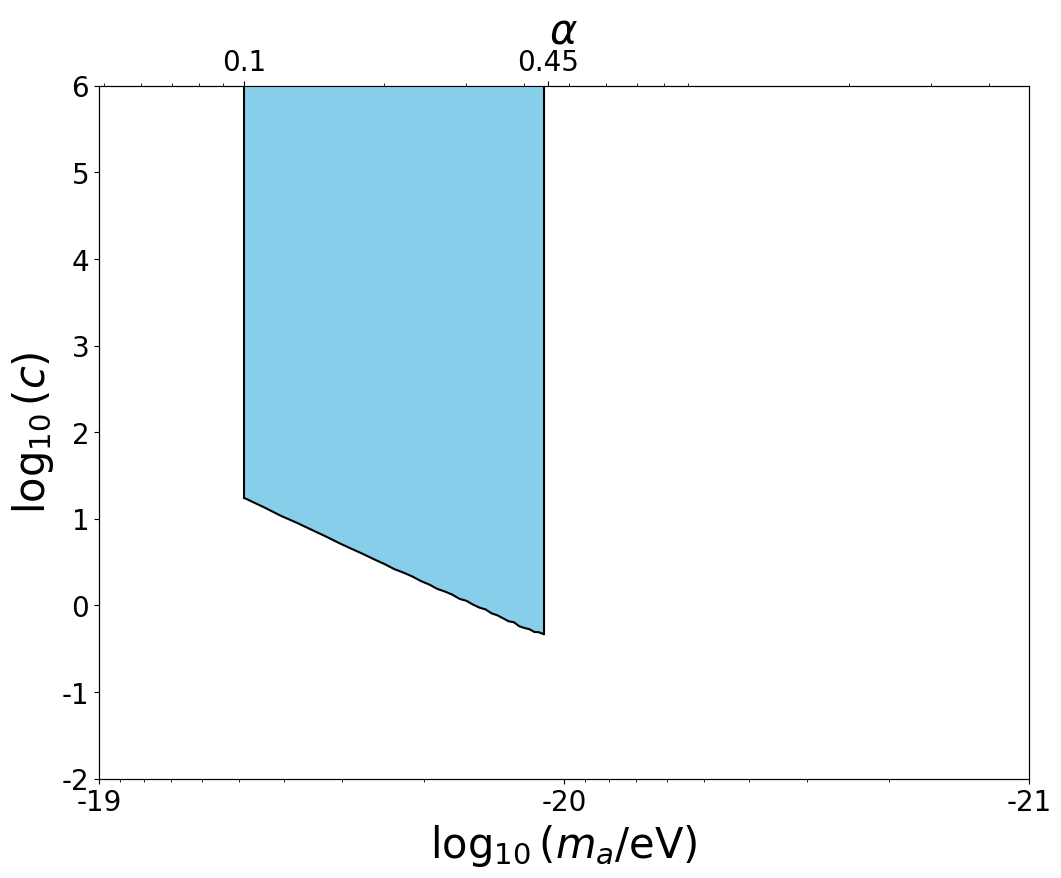

In [50]:
get_final_cut_1d(mode="std")

(27, 27)
[ 9.9502881   9.97951728 11.28501616 11.6371526  12.11459544 12.89496322
 13.14196929 15.03003174 15.36312105 15.46607233 16.76606153 17.57612779
 17.86231376 21.96384973 28.34078708 28.8487039  28.99893374 29.03256839
 34.02817148 37.31279907 38.58955229 41.8978292  41.94627861 47.67006147
 48.37117041 48.52036589 53.66436308]
[10.95054419 14.61955475 16.32110465 22.80070414 22.90004647 23.71443695
 25.57279646 25.85749789 29.94627788 33.89688266 34.99030661 35.1801448
 35.23826176 37.08801237 37.40294403 38.18324153 39.72428644 40.08746699
 40.26593274 41.63232311 43.31346967 44.53422008 44.7462181  44.91614491
 47.73215129 48.76496808 53.95570202]
0 is done!
(27, 27)
[ 9.9502881   9.97951728 11.28501616 11.6371526  12.11459544 12.89496322
 13.14196929 15.03003174 15.36312105 15.46607233 16.76606153 17.57612779
 17.86231376 21.96384973 28.34078708 28.8487039  28.99893374 29.03256839
 34.02817148 37.31279907 38.58955229 41.8978292  41.94627861 47.67006147
 48.37117041 48.5203

[np.float64(1.4862498074667148),
 np.float64(1.3911229120280202),
 np.float64(1.2881326043581),
 np.float64(1.2134088378967067),
 np.float64(1.122738879705287),
 np.float64(1.0456075028830274),
 np.float64(0.9812595518751833),
 np.float64(0.908032286508608),
 np.float64(0.8548701640588358),
 np.float64(0.7945175084403617),
 np.float64(0.7345584452092508),
 np.float64(0.6860551306981513),
 np.float64(0.6375806877075811),
 np.float64(0.5975151059221163),
 np.float64(0.5463158859139656),
 np.float64(0.4988623164666512),
 np.float64(0.4582000044795544),
 np.float64(0.41949102691749574),
 np.float64(0.3835527489764203),
 np.float64(0.3373251683246109),
 np.float64(0.3026687897763084),
 np.float64(0.2676707685549472),
 np.float64(0.23235408930179063),
 np.float64(0.2028375496872109),
 np.float64(0.16303077990036813),
 np.float64(0.1398666780379048),
 np.float64(0.10657654790036875),
 np.float64(0.07214975434227112),
 np.float64(0.05710132976800324),
 np.float64(0.02141193608580151),
 np.floa

<Figure size 640x480 with 0 Axes>

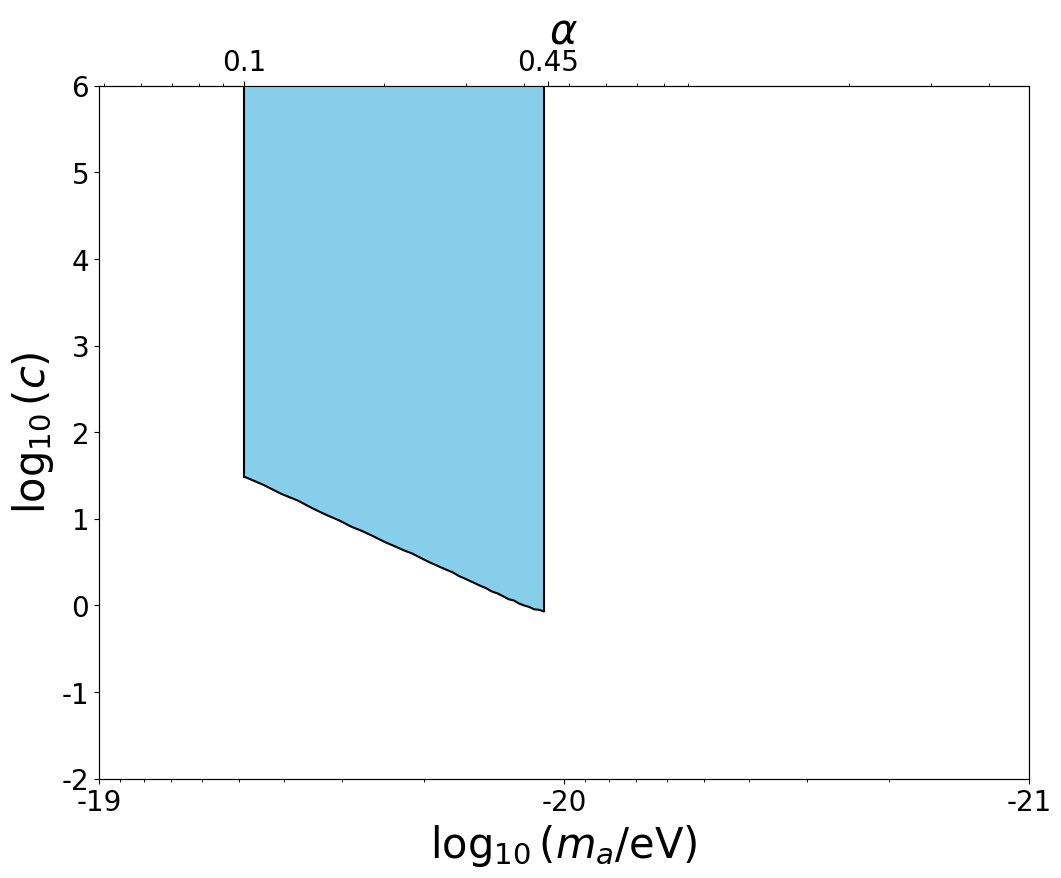

In [51]:
get_final_cut_1d(mode="cor")

(27, 27)
[ 9.9502881   9.97951728 11.28501616 11.6371526  12.11459544 12.89496322
 13.14196929 15.03003174 15.36312105 15.46607233 16.76606153 17.57612779
 17.86231376 21.96384973 28.34078708 28.8487039  28.99893374 29.03256839
 34.02817148 37.31279907 38.58955229 41.8978292  41.94627861 47.67006147
 48.37117041 48.52036589 53.66436308]
[10.95054419 14.61955475 16.32110465 22.80070414 22.90004647 23.71443695
 25.57279646 25.85749789 29.94627788 33.89688266 34.99030661 35.1801448
 35.23826176 37.08801237 37.40294403 38.18324153 39.72428644 40.08746699
 40.26593274 41.63232311 43.31346967 44.53422008 44.7462181  44.91614491
 47.73215129 48.76496808 53.95570202]
0 is done!
(27, 27)
[ 9.9502881   9.97951728 11.28501616 11.6371526  12.11459544 12.89496322
 13.14196929 15.03003174 15.36312105 15.46607233 16.76606153 17.57612779
 17.86231376 21.96384973 28.34078708 28.8487039  28.99893374 29.03256839
 34.02817148 37.31279907 38.58955229 41.8978292  41.94627861 47.67006147
 48.37117041 48.5203

[np.float64(1.5393492730252492),
 np.float64(1.4431215442132364),
 np.float64(1.3430523620870267),
 np.float64(1.2649964425199316),
 np.float64(1.1717341394279273),
 np.float64(1.098824775295876),
 np.float64(1.0262185131481107),
 np.float64(0.9513403234550503),
 np.float64(0.8994124531008625),
 np.float64(0.8322090168613837),
 np.float64(0.7788609957173993),
 np.float64(0.7234850995545005),
 np.float64(0.6767437076290918),
 np.float64(0.6355356037859141),
 np.float64(0.5829984001855352),
 np.float64(0.5370465531128403),
 np.float64(0.49323906122451994),
 np.float64(0.4558741833543454),
 np.float64(0.4182647381260509),
 np.float64(0.3715893597492251),
 np.float64(0.34025733575568123),
 np.float64(0.29874443136961926),
 np.float64(0.2649029882533153),
 np.float64(0.23855882167047848),
 np.float64(0.19172921836269763),
 np.float64(0.17044826845957056),
 np.float64(0.1385314940789525),
 np.float64(0.1004678683645722),
 np.float64(0.08493713651973098),
 np.float64(0.049380775066453206),
 n

<Figure size 640x480 with 0 Axes>

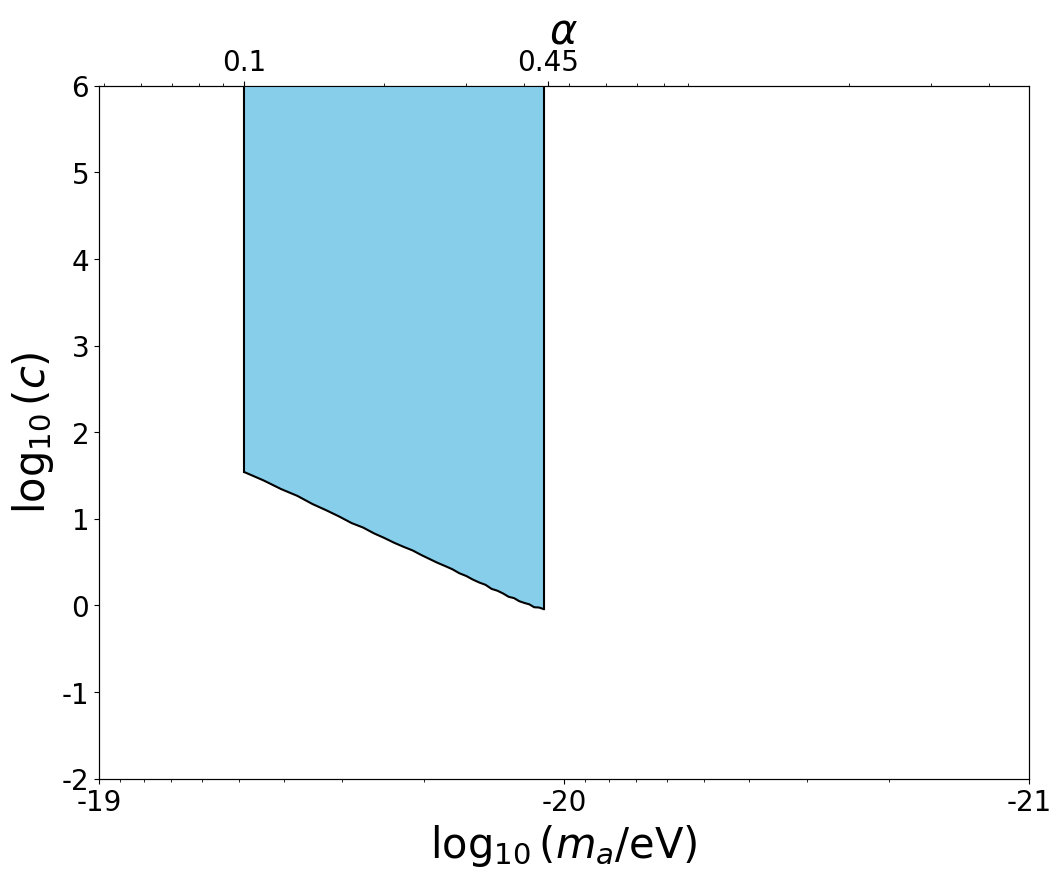

In [52]:
get_final_cut_1d(mode="cor_grmhd")

In [ ]:
np.sqrt(np.diag(cor_std_good[0])) / np.pi * 180

array([11.7563888 , 13.45154066, 26.38031961, 31.96265062, 21.22161131,
       18.93035074, 24.15504967, 26.65206932, 34.72027064, 19.61024197,
       14.58457443, 22.79992831, 20.15230603, 10.83766744, 10.34497303,
       11.43059054,  8.3288432 ])

In [ ]:
np.sqrt(np.diag(cor_std_good[0])) / np.pi * 180

array([11.43107396, 15.33082919, 29.91254594, 29.67396822, 24.92765656,
       19.30193136, 19.63667278, 25.56671903, 30.88545625, 34.37667603,
       23.72729762, 17.86171389, 15.92704258, 24.62061043,  7.95199034,
        9.91025657, 11.0482334 ,  9.84320908,  8.95129117, 10.55465118,
        7.60775649,  9.84547076])

In [220]:
final_cut

[np.float64(1.5312097620530989),
 np.float64(1.4369922722548818),
 np.float64(1.3398664207182276),
 np.float64(1.2533050079370815),
 np.float64(1.1680689398041517),
 np.float64(1.0922639381054249),
 np.float64(1.0208087835671018),
 np.float64(0.9512602095596117),
 np.float64(0.892502354155284),
 np.float64(0.8299052205634789),
 np.float64(0.7771637013990488),
 np.float64(0.723444582924998),
 np.float64(0.6786603392143057),
 np.float64(0.6328808033549145),
 np.float64(0.5861357086259048),
 np.float64(0.5412614126708223),
 np.float64(0.4991554791986416),
 np.float64(0.46258612307255254),
 np.float64(0.4236982486003438),
 np.float64(0.38387965961361864),
 np.float64(0.3515133215340765),
 np.float64(0.31349569413989065),
 np.float64(0.28013621230374697),
 np.float64(0.25094397114453676),
 np.float64(0.2136732520256614),
 np.float64(0.18553802007646877),
 np.float64(0.15671673509633913),
 np.float64(0.12592751148642095),
 np.float64(0.10187890903131192),
 np.float64(0.07255590864652472),
 n

In [207]:
final_cut

[np.float64(1.5028934084145136),
 np.float64(1.3939294101656103),
 np.float64(1.2984880164334047),
 np.float64(1.219521044625946),
 np.float64(1.1228947218706897),
 np.float64(1.0545351709889288),
 np.float64(0.9830719027876236),
 np.float64(0.9113186129136752),
 np.float64(0.8586672714176375),
 np.float64(0.7920957763987064),
 np.float64(0.7399947843873623),
 np.float64(0.6892863898285836),
 np.float64(0.6364081696191491),
 np.float64(0.5964752515228422),
 np.float64(0.5433239255800661),
 np.float64(0.4976455755368914),
 np.float64(0.4546506037196992),
 np.float64(0.40851450500056574),
 np.float64(0.37482212559147965),
 np.float64(0.3284562287731632),
 np.float64(0.2921153171488353),
 np.float64(0.2554134588560792),
 np.float64(0.21612976050799518),
 np.float64(0.1850722515333471),
 np.float64(0.1482043316761318),
 np.float64(0.11782979958308852),
 np.float64(0.08324602656325561),
 np.float64(0.05424944300450993),
 np.float64(0.030452466188061765),
 np.float64(-0.0037480913606893432),

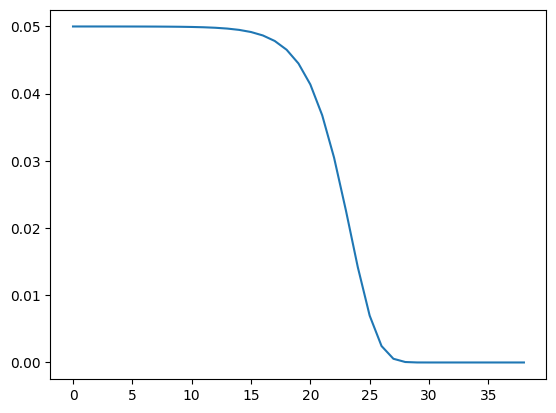

In [231]:
plt.plot(np.diff(prgagg))

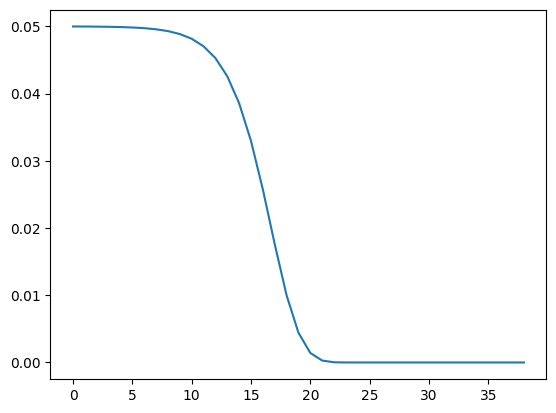

In [228]:
plt.plot(np.diff(prgagg))

In [ ]:
final_cut1 = np.load("M_all/new_static/l_cor_dyn_obs.npz")
final_cut2 = np.load("new_static/l_cor_1d.npz")

<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_497813/3991053186.py:9: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel('$\log_{10}(c)$',size=30)
/tmp/ipykernel_497813/3991053186.py:17: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('$\log_{10}(m_a/\mathrm{eV})$',size=30)


<Figure size 640x480 with 0 Axes>

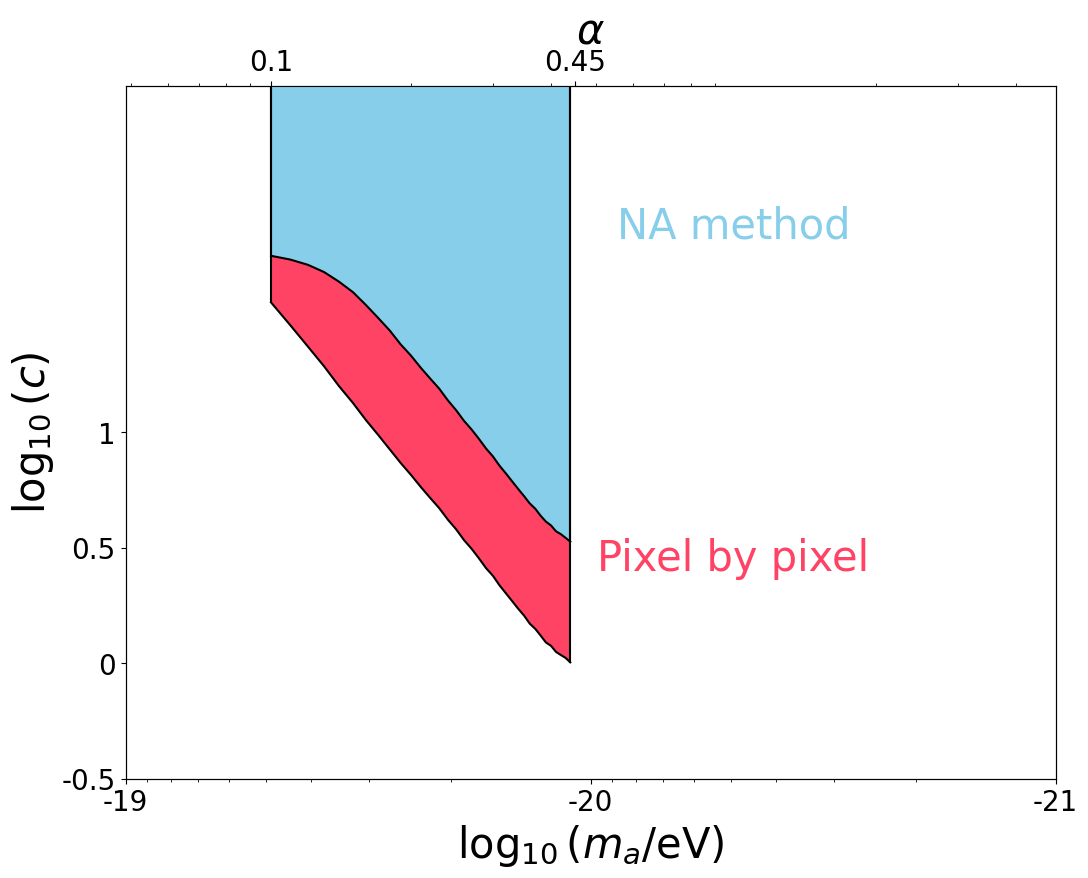

In [ ]:
plt.clf()
fig, ax = plt.subplots(figsize=(12, 9))
ax.set_xscale("log")
ax2 = ax.twiny()
ax2.set_xscale("log")
ax.set_ylim(-0.5, 2.5)
ax.set_yticks([-0.5, 0, 0.5, 1])
ax.set_yticklabels(["-0.5", "0", "0.5", "1"], size=20)
ax.set_ylabel("$\log_{10}(c)$", size=30)
ax2.set_xticks([0.1, 0.45])
ax2.set_xticklabels(["0.1", "0.45"], size=20)
ax2.set_xlabel(r"$ \alpha $", size=30)
ax2.set_xlim(0.0486495, 4.86495)
ax.set_xlim(1e-19, 1e-21)
ax.set_xticks([1e-21, 1e-20, 1e-19])
ax.set_xticklabels(["-21", "-20", "-19"], size=20)
ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)
temp = np.load("new_static/l_cor_1d.npz")
x1 = temp["omegas"]
y1 = temp["cuts"]
yarray1 = deepcopy(y1)
temp = np.load("M_all/new_static/l_cor_dyn_obs.npz")
x2 = temp["omegas"]
y2 = temp["cuts"]
# y2[-2] = -1.09
# y2[-1] = -1.12
yarray2 = deepcopy(y2)


# for i in range(1,len(y2)-1):
#     yarray1[i] = (y1[i-1]+y1[i]+y1[i+1])/3.
#     yarray2[i] = (y2[i-1]+y2[i]+y2[i+1])/3.

ax2.plot(x1, yarray1, "black")
ax2.plot([np.max(x1), np.max(x1)], [yarray1[-1], 6], "black")
ax2.plot([np.min(x1), np.min(x1)], [yarray1[0], 6], "black")
ax2.plot(x2, yarray2, "black")
ax2.plot([np.max(x1), np.max(x1)], [yarray2[-1], 6], "black")
ax2.plot([np.min(x1), np.min(x1)], [yarray2[0], 6], "black")
xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
ax2.fill_between(x1, yarray1, 3, ls="-", lw=2, fc=xcolor[0], alpha=1)
ax2.fill_between(x1, yarray2, yarray1, ls="-", lw=2, fc=xcolor[2], alpha=1)
plt.annotate(
    "NA method",
    xy=(0.78, 0.78),
    xycoords="axes fraction",
    ha="right",
    size=30,
    color=xcolor[0],
)
plt.annotate(
    "Pixel by pixel",
    xy=(0.8, 0.3),
    xycoords="axes fraction",
    ha="right",
    size=30,
    color=xcolor[2],
)
plt.savefig(f"new_static/contract.pdf", dpi=600)

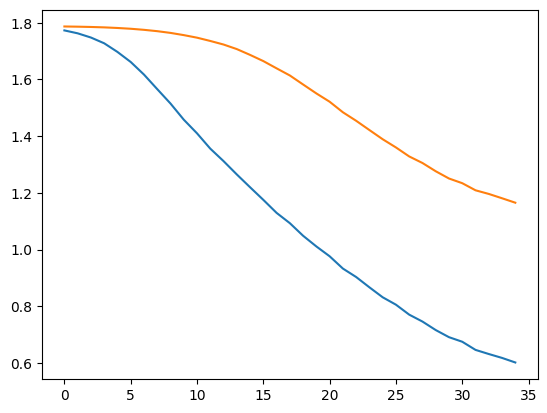

In [170]:
plt.plot(final_cut1["cuts"])
plt.plot(final_cut2["cuts"])

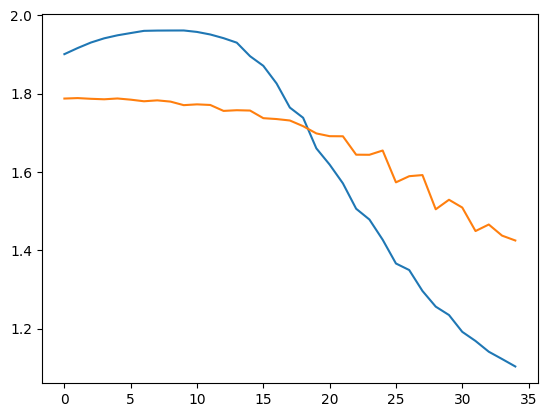

In [160]:
plt.plot(final_cut1["cuts"])
plt.plot(final_cut2["cuts"])

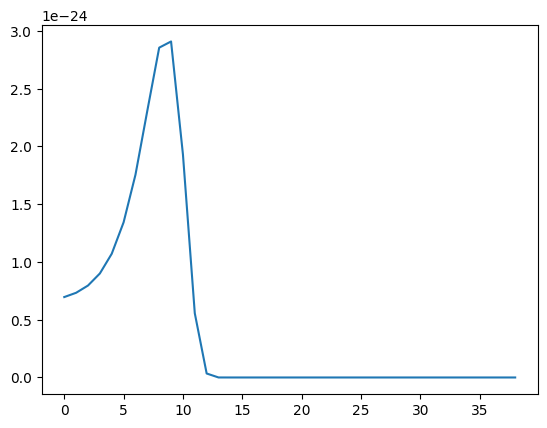

In [32]:
plt.plot(np.diff(prgagg))

In [ ]:
final_cut[34] - final_cut[0]

np.float64(-1.3126400088088257)

In [ ]:
All_data = np.load(f"./EHT-Imaging/101_all_data.npy")
theta_data101 = 0.5 * np.arctan2(
    np.mean(All_data[:, :, :, 2], axis=0), np.mean(All_data[:, :, :, 1], axis=0)
)  # rad

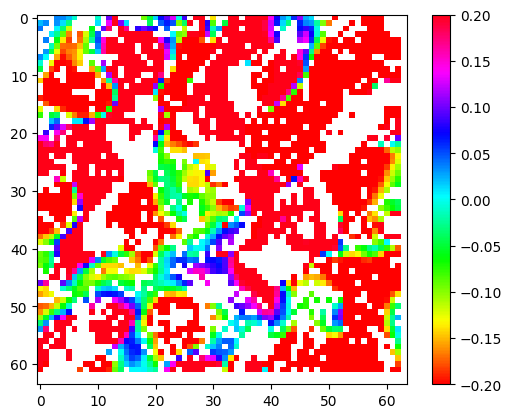

In [ ]:
plt.imshow(CircleCalc.circle_sub_evpa(theta_mean[1], theta_mean[0]), cmap="hsv")
plt.colorbar()
plt.clim(-0.2, 0.2)

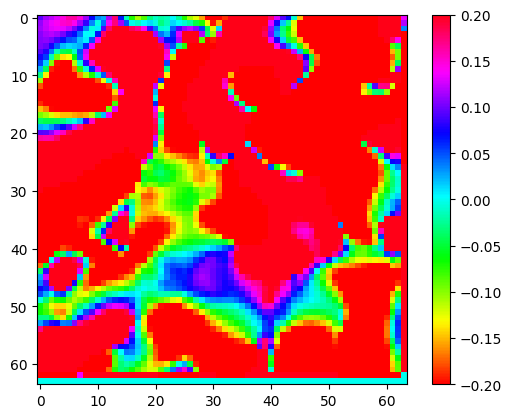

In [ ]:
plt.imshow(CircleCalc.circle_sub_evpa(theta_data96, theta_data95), cmap="hsv")
plt.colorbar()
plt.clim(-0.2, 0.2)

In [ ]:
jj = theta_mean[1] - theta_mean[0]
jj[np.sqrt(theta_std[1] * theta_std[1] + theta_std[0] * theta_std[0]) > 0.3] = np.nan

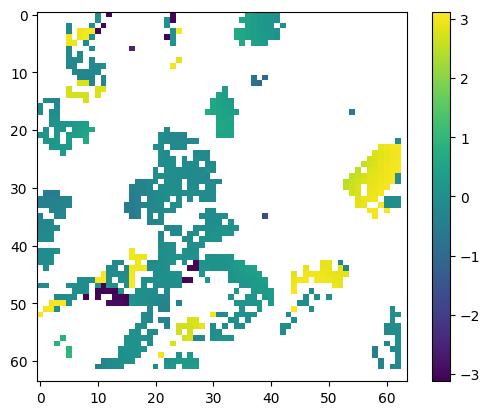

In [137]:
plt.imshow(jj)
plt.colorbar()
# plt.clim(-0.2,0.2)

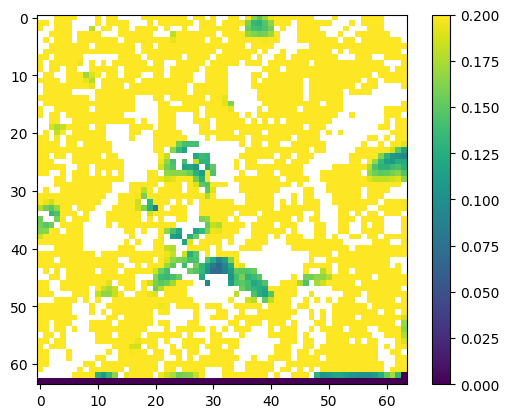

In [ ]:
plt.imshow(np.sqrt(theta_std[1] * theta_std[1] + theta_std[0] * theta_std[0]))
plt.colorbar()
plt.clim(0, 0.2)

In [ ]:
cor_std_good[0, 1, 1]

np.float64(0.4512943525439286)

In [ ]:
(np.asarray([np.diag(Delta_std[0]), np.diag(Delta_std[1])])[:, goodsetrow, goodsetcol])[
    0
].min()

np.float64(0.0)

In [ ]:
jj = np.asarray([np.diag(Delta_std[0]), np.diag(Delta_std[1])])[
    :, goodsetrow, goodsetcol
]

In [ ]:
np.array([jj[1, i, i] for i in range(237)]).min()

np.float64(0.11598372425616639)

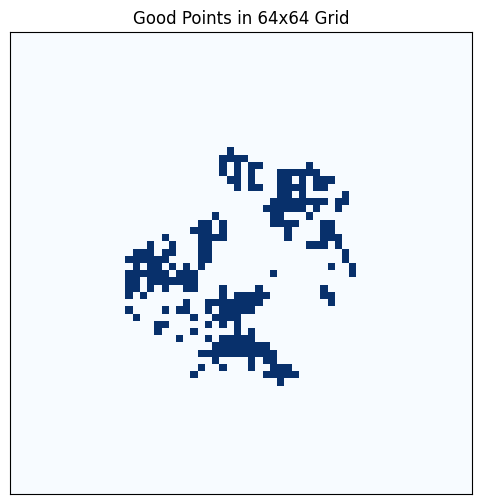

In [ ]:
grid = np.zeros((64, 64))

# 把 goodset 里的点设为 1
for num in goodset:
    x, y = divmod(num, 64)
    grid[x, y] = 1

# 画图
plt.figure(figsize=(6, 6))
plt.imshow(grid, cmap="Blues", origin="upper")  # 颜色用蓝色
plt.xticks([])
plt.yticks([])
plt.title("Good Points in 64x64 Grid")
plt.show()

In [ ]:
[cor_std + cor_grmhd + tmpCorAxion[i] * (gagg[g] * gagg[g]) for i in range(16)]

[array([[[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan,  0.,  0.],
         [nan, nan, nan, ...,  0., nan,  0.],
         [nan, nan, nan, ...,  0.,  0., nan]],
 
        [[nan,  0.,  0., ..., nan, nan,  0.],
         [ 0., nan,  0., ..., nan, nan,  0.],
         [ 0.,  0., nan, ..., nan, nan,  0.],
         ...,
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [ 0.,  0.,  0., ..., nan, nan, nan]]]),
 array([[[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan,  0.,  0.],
         [nan, nan, nan, ...,  0., nan,  0.],
         [nan, nan, nan, ...,  0.,  0., nan]],
 
        [[nan,  0.,  0., ..., nan, nan,  0.],
         [ 0., nan,  0., ..., nan, nan,  0.],
         [ 0.,  0., nan, ...,

In [83]:
final_cut

[np.float64(1.501703368559929),
 np.float64(1.4906423571358534),
 np.float64(1.4007462096465821),
 np.float64(1.2690943382366104),
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [ ]:
theta_data_1d_786[theta_data_1d_786 > np.pi / 2] -= np.pi
theta_data_1d_786[theta_data_1d_786 < -np.pi / 2] += np.pi

In [ ]:
np.save("Plot/theta_data_1d_786_4", theta_data_1d_786)